In [1]:
# ==============================================================================
# 0. SETUP AND IMPORTS
# ==============================================================================

# --- Import Libraries ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from google.colab import drive

# --- Mount Google Drive ---
# This allows the notebook to access files stored in your Google Drive.
# You will be prompted for authorization the first time you run this.
print("Mounting Google Drive...")
drive.mount('/content/drive')
print("Drive mounted successfully.")

Mounting Google Drive...
Mounted at /content/drive
Drive mounted successfully.


In [2]:
# ==============================================================================
# 1. DATA LOADING AND PRE-PROCESSING
# ==============================================================================

# --- Constants & Configuration ---
INPUT_FILE_PATH = '/content/drive/MyDrive/IFMHA/ifmha_subset_stat.csv'

# Unit Conversion Factors
CFS_TO_M3S = 0.028316832  # Cubic feet per second to Cubic meters per second
FT_TO_M = 0.3048          # Feet to Meters

# --- Load the Dataset ---
# 'site_no' is read as a string to preserve leading zeros.
# 'low_memory=False' is used to handle mixed types in larger files efficiently.
try:
    ifmha_subset_stat = pd.read_csv(
        INPUT_FILE_PATH,
        converters={'site_no': str},
        low_memory=False
    )
    print(f"Data loaded successfully.")
    print(f"DataFrame Shape: {ifmha_subset_stat.shape}")

except FileNotFoundError:
    print(f"ERROR: File not found at '{INPUT_FILE_PATH}'.")
    print("Please verify the Google Drive path.")
    exit()  # Stop execution if data is missing

# --- Perform Unit Conversions ---
# Create new columns for metric units using the defined conversion factors.

# 1. Discharge: cfs -> m³/s
ifmha_subset_stat['discharge_m3s'] = ifmha_subset_stat['discharge_va'] * CFS_TO_M3S

# 2. Stage: ft -> m
ifmha_subset_stat['stage_m'] = ifmha_subset_stat['gage_height_va'] * FT_TO_M

Data loaded successfully.
DataFrame Shape: (2064782, 49)



Found 6494 sites with valid data for plotting.
Generating plots for 20 sites...


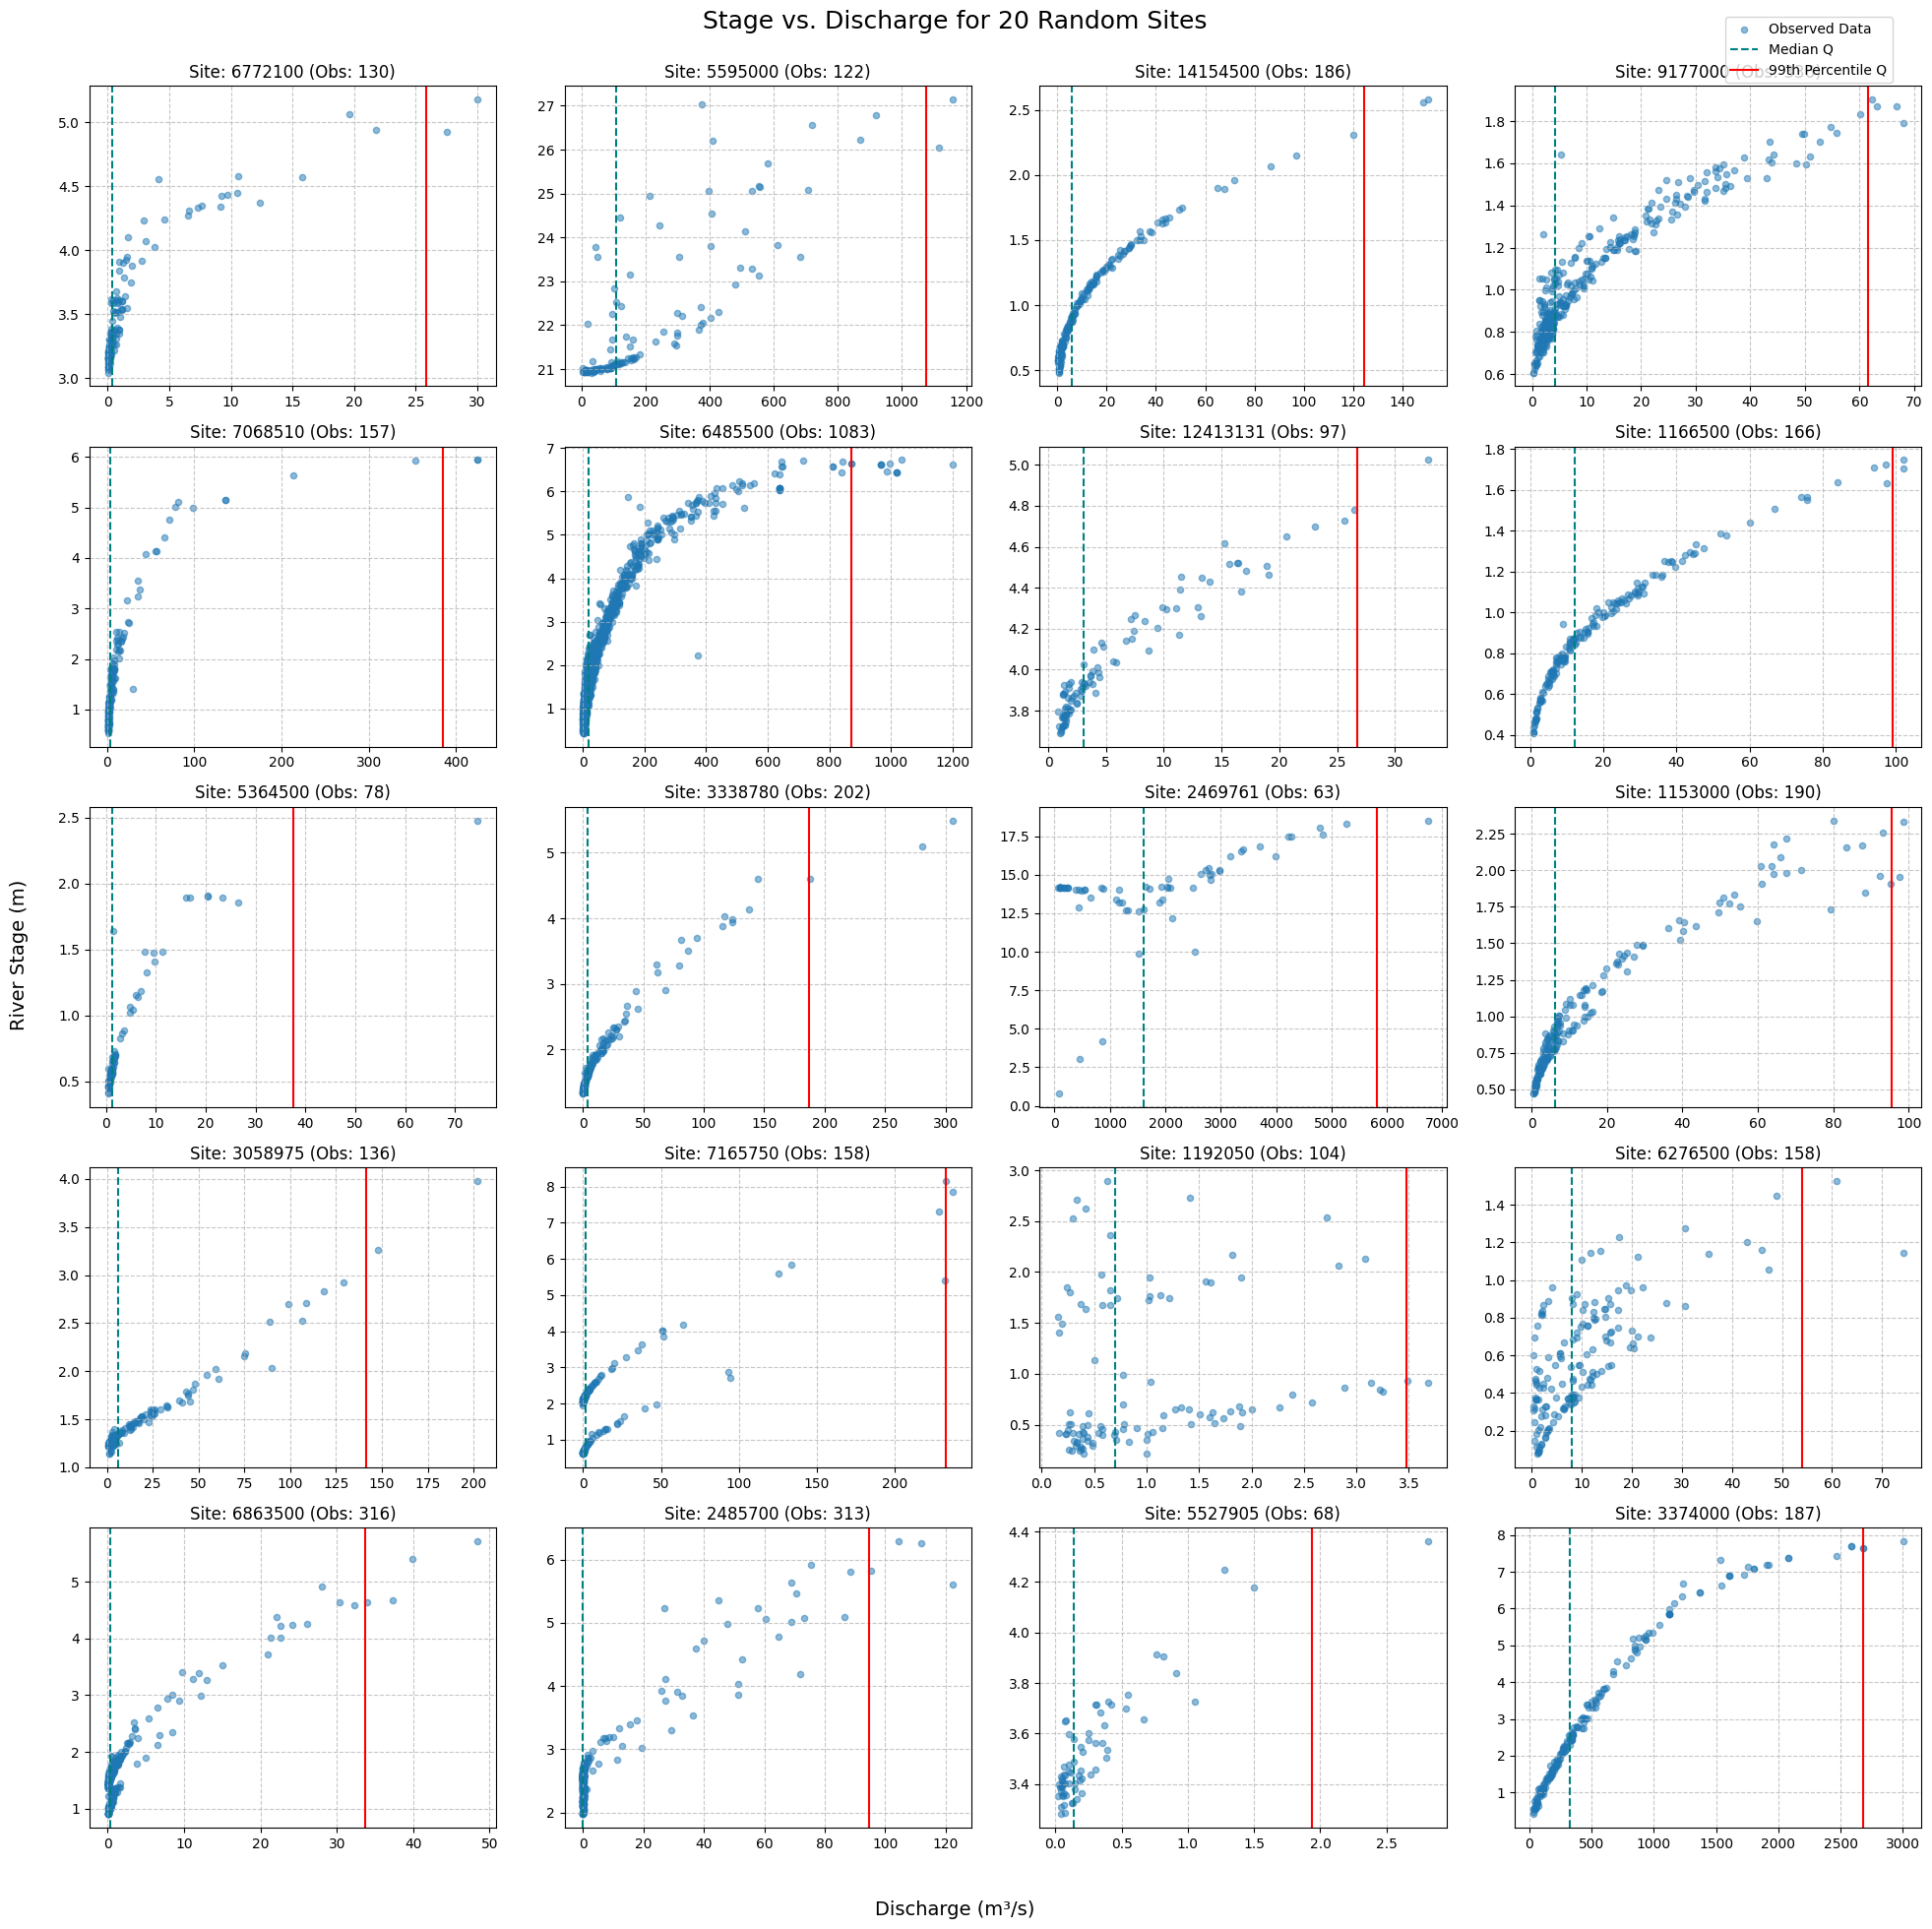

In [3]:
# ==============================================================================
# 2. EXPLORATORY VISUALIZATION OF RANDOM SITES
# ==============================================================================

# --- Configuration ---
# Set parameters for the visualization grid.
NUM_SITES_TO_PLOT = 20  # Total number of random sites to visualize
N_COLS = 4              # Number of columns in the subplot grid
RANDOM_SEED = 42        # Seed for reproducibility of random selection

# --- Group Data by Site ---
# We group the main dataframe by 'site_no' to access individual site records easily.
# We also drop rows with missing gage height as it's required for plotting.
grouped_ifmha = ifmha_subset_stat.dropna(subset=['gage_height_va']).groupby('site_no')
site_no_list = list(grouped_ifmha.groups.keys())

print(f"\nFound {len(site_no_list)} sites with valid data for plotting.")

# --- Select Random Sites ---
# Ensure we don't try to plot more sites than exist in the data.
num_sites_to_plot = min(NUM_SITES_TO_PLOT, len(site_no_list))

# Randomly select site indices using a fixed seed for consistent results.
rng = np.random.default_rng(RANDOM_SEED)
random_indices = rng.choice(len(site_no_list), num_sites_to_plot, replace=False)
selected_sites = [site_no_list[i] for i in random_indices]

print(f"Generating plots for {num_sites_to_plot} sites...")

# --- Create Subplot Grid ---
# Calculate required rows based on the number of plots and columns.
n_rows = math.ceil(num_sites_to_plot / N_COLS)
fig, axes = plt.subplots(nrows=n_rows, ncols=N_COLS, figsize=(20, 4 * n_rows))

# Flatten axes array for easy iteration (handles both 1D and 2D arrays).
axes_flat = axes.flatten()

# --- Plotting Loop ---
for idx, sn in enumerate(selected_sites):
    ax = axes_flat[idx]

    # 1. Get Data for Site
    df = grouped_ifmha.get_group(sn)
    q = df["discharge_m3s"]
    s = df["stage_m"]

    # 2. Filter Extreme Outliers (Visual Clean-up)
    # We remove the top and bottom 1% of stage values to focus the plot on the
    # main body of data. This is strictly for visualization purposes here.
    lower_bound = s.quantile(0.01)
    upper_bound = s.quantile(0.99)
    is_within_quantiles = (s > lower_bound) & (s < upper_bound)

    q_filtered = q[is_within_quantiles]
    s_filtered = s[is_within_quantiles]

    # 3. Create Scatter Plot
    ax.scatter(q_filtered, s_filtered, alpha=0.5, s=20, label='Observed Data')

    # 4. Add Reference Lines
    median_q = q_filtered.median()
    percentile_99_q = q_filtered.quantile(0.99)

    ax.axvline(x=median_q, color='teal', linestyle='--', label='Median Q')
    ax.axvline(x=percentile_99_q, color='red', linestyle='-', label='99th Percentile Q')

    # 5. Set Title and Grid
    ax.set_title(f"Site: {sn} (Obs: {len(q_filtered)})")
    ax.grid(True, linestyle='--', alpha=0.7)

# --- Final Figure Formatting ---

# 1. Hide Unused Subplots
# If the number of sites doesn't fill the last row, hide the empty axes.
for i in range(num_sites_to_plot, len(axes_flat)):
    axes_flat[i].axis('off')

# 2. Add Shared Legend
# We use the handles/labels from the first plot (index 0) for the shared legend.
handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.98, 0.98))

# 3. Add Shared Axis Labels
fig.supxlabel('Discharge (m³/s)', fontsize=14)
fig.supylabel('River Stage (m)', fontsize=14)

# 4. Final Layout Adjustments
plt.tight_layout(rect=[0.02, 0.02, 1, 0.96])
fig.suptitle(f"Stage vs. Discharge for {num_sites_to_plot} Random Sites", fontsize=18)

plt.show()

In [4]:
# ==============================================================================
# 3. DATASET STRUCTURE AND COLUMN ANALYSIS
# ==============================================================================

# --- 1. List all columns ---
print("### Column Names ###")
print(ifmha_subset_stat.columns.tolist())
print("-" * 30)

# --- 2. Get Data Types and Non-Null Counts ---
# This helps identify which columns are numeric vs. categorical
print("### Dataset Info ###")
print(ifmha_subset_stat.info())
print("-" * 30)

# --- 3. Preview the first few rows ---
# This gives you a 'human-readable' look at the actual data
print("### Data Preview (Top 5 Rows) ###")
display(ifmha_subset_stat.head())

### Column Names ###
['site_no', 'COMID', 'DASqKm', 'DASqMi', 'FTYPE', 'LatSite', 'LonSite', 'SLOPE', 'STATE', 'STATE_CD', 'StreamOrde', 'chan_area', 'chan_discharge', 'chan_evenness', 'chan_loc_cd', 'chan_loc_dist', 'chan_material', 'chan_name', 'chan_nu', 'chan_stability', 'chan_velocity', 'chan_width', 'contrib_drain_area_va', 'control_type_cd', 'dec_lat_va', 'dec_long_va', 'discharge_cd', 'discharge_va', 'drain_area_va', 'gage_height_va', 'gage_va_change', 'gage_va_time', 'horz_vel_desc', 'long_vel_desc', 'meas_type', 'measured_rating_diff', 'measurement_dt', 'measurement_nu', 'party_nm', 'q_meas_used_fg', 'site_tp_cd', 'site_visit_coll_agency_cd', 'station_nm', 'streamflow_method', 'tz_cd', 'velocity_method', 'vert_vel_desc', 'chan_mean_depth', 'chan_max_depth', 'discharge_m3s', 'stage_m']
------------------------------
### Dataset Info ###
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2064782 entries, 0 to 2064781
Data columns (total 51 columns):
 #   Column                  

,site_no,COMID,DASqKm,DASqMi,FTYPE,LatSite,LonSite,SLOPE,STATE,STATE_CD,...,site_visit_coll_agency_cd,station_nm,streamflow_method,tz_cd,velocity_method,vert_vel_desc,chan_mean_depth,chan_max_depth,discharge_m3s,stage_m
0,1010000,4289887.0,3473.19,1341.0,ArtificialPath,46.700556,-69.715556,0.003156,ME,23.0,...,USGS,"St. John River at Ninemile Bridge, Maine",unspe,NaN,unkno,UNSP,0.766562,1.107819,5.748317,0.240792
1,1010000,4289887.0,3473.19,1341.0,ArtificialPath,46.700556,-69.715556,0.003156,ME,23.0,...,USGS,"St. John River at Ninemile Bridge, Maine",QSCMM,NaN,unkno,UNSP,2.612188,3.837696,70.225743,NaN
2,1010000,4289887.0,3473.19,1341.0,ArtificialPath,46.700556,-69.715556,0.003156,ME,23.0,...,USGS,"St. John River at Ninemile Bridge, Maine",unspe,EDT,unkno,UNSP,1.766667,2.587080,48.138614,0.798576
3,1010000,4289887.0,3473.19,1341.0,ArtificialPath,46.700556,-69.715556,0.003156,ME,23.0,...,USGS,"St. John River at Ninemile Bridge, Maine",unspe,NaN,unkno,UNSP,0.962617,1.397805,19.651881,0.524256
4,1010000,4289887.0,3473.19,1341.0,ArtificialPath,46.700556,-69.715556,0.003156,ME,23.0,...,USGS,"St. John River at Ninemile Bridge, Maine",QSCMM,NaN,unkno,UNSP,0.821429,1.188973,5.918218,NaN


✅ Successfully extracted 1102 records for Site 6606600
   COMID: 14624658.0
   Data cleaning complete. 1069 rows remain for modeling.

✅ Rating Curve Fitting Successful:
   C = 1.470
   n = 2.909
   H0 = -0.326


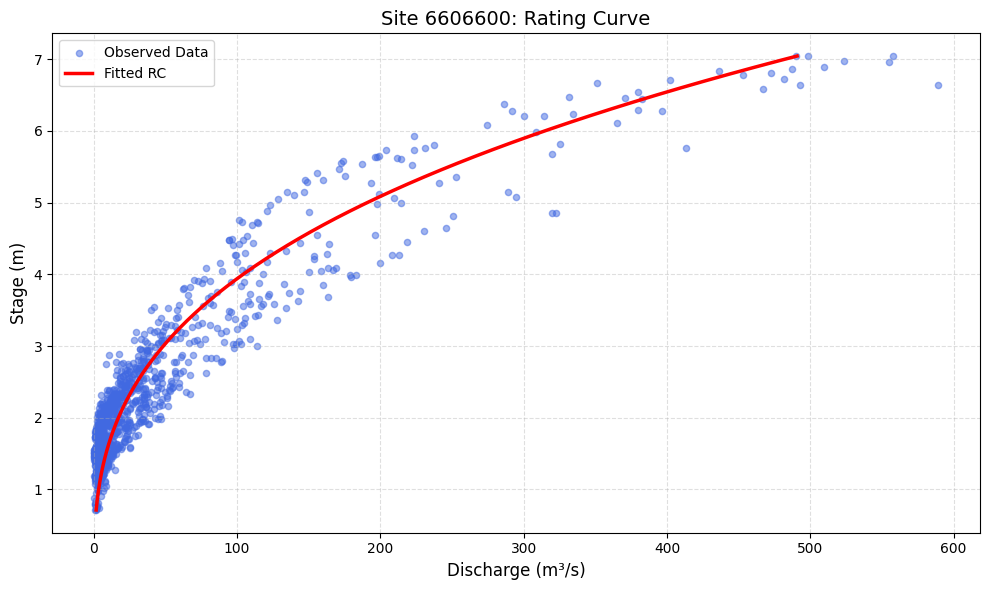

In [5]:
# ==============================================================================
# 3. TARGET SITE ANALYSIS: SELECTION, EXTRACTION, AND RATING CURVE FIT
# ==============================================================================

from scipy.optimize import curve_fit

# --- Configuration ---
TARGET_SITE = '6606600'  # The specific USGS site number to analyze

# --- 1. Data Extraction ---
# We verify if the site exists in the dataset and extract its records.
if TARGET_SITE in ifmha_subset_stat['site_no'].unique():
    # Use .copy() to avoid SettingWithCopy warnings on subsequent edits
    site_df = ifmha_subset_stat[ifmha_subset_stat['site_no'] == TARGET_SITE].copy()

    # Retrieve the COMID (Common Identifier) for later use with external datasets
    comid_value = site_df['COMID'].iloc[0]

    print(f"✅ Successfully extracted {len(site_df)} records for Site {TARGET_SITE}")
    print(f"   COMID: {comid_value}")
else:
    print(f"❌ ERROR: Site {TARGET_SITE} not found in the dataset.")
    print("   Please verify the site number.")
    # Stop execution if site is missing to prevent errors downstream
    raise ValueError(f"Site {TARGET_SITE} not found.")

# --- 2. Data Cleaning for Modeling ---
# We prepare the data for the rating curve fit by removing N/A values and
# filtering out extreme outliers (top/bottom 1%) to ensure a robust fit.

# Create a subset with only necessary columns
obs_df = site_df[['discharge_m3s', 'stage_m']].dropna().copy()

# Calculate quantiles for filtering
q_lo, q_hi = obs_df['discharge_m3s'].quantile([0.01, 0.99])
h_lo, h_hi = obs_df['stage_m'].quantile([0.01, 0.99])

# Apply the filter
obs_df_filtered = obs_df[
    (obs_df['discharge_m3s'] >= q_lo) & (obs_df['discharge_m3s'] <= q_hi) &
    (obs_df['stage_m'] >= h_lo) & (obs_df['stage_m'] <= h_hi)
].copy()

print(f"   Data cleaning complete. {len(obs_df_filtered)} rows remain for modeling.")

# --- 3. Define Rating Curve Model ---
def rating_curve_model(H, C, n, H0):
    """
    Standard Power-law model for rating curve: Q = C * (H - H0)^n
    H  : Stage (m)
    C  : Coefficient
    n  : Exponent (typically ~2.0 for natural channels)
    H0 : Stage at zero flow (m)
    """
    # np.maximum ensures we don't take the root of a negative number
    return C * np.maximum(0.0, H - H0) ** n

# --- 4. Fit the Rating Curve ---
# Extract arrays for scipy.optimize
Q_obs = obs_df_filtered['discharge_m3s'].values
H_obs = obs_df_filtered['stage_m'].values

try:
    # A. Initial Parameter Guesses (Heuristic)
    H0_guess = H_obs.min() * 0.95
    # Estimate C based on mean values and H0 guess
    C_guess = Q_obs.mean() / max((H_obs.mean() - H0_guess)**2.0, 1e-8)

    # Initial parameter vector: [C, n, H0]
    p0 = [C_guess, 2.0, H0_guess]

    # B. Define Bounds for Optimization
    # C > 0, n > 0, H0 constrained near minimum observed stage
    bounds = (
        [0.0, 0.0, H_obs.min() - 5.0],   # Lower bounds
        [np.inf, 5.0, H_obs.min() + 0.5] # Upper bounds
    )

    # C. Run Optimization
    (C_fit, n_fit, H0_fit), _ = curve_fit(
        rating_curve_model, H_obs, Q_obs,
        p0=p0, bounds=bounds, maxfev=20000
    )

    print("\n✅ Rating Curve Fitting Successful:")
    print(f"   C = {C_fit:.3f}")
    print(f"   n = {n_fit:.3f}")
    print(f"   H0 = {H0_fit:.3f}")

except Exception as e:
    print(f"\n❌ Rating curve fitting failed for Site {TARGET_SITE}.")
    print(f"   Error details: {e}")
    # Set placeholders to allow code to continue (or choose to exit here)
    C_fit, n_fit, H0_fit = np.nan, np.nan, np.nan

# --- 5. Visualization ---
# Generate a smooth curve using the fitted parameters
H_grid_rc = np.linspace(H_obs.min(), H_obs.max(), 200)
Q_fit_rc = rating_curve_model(H_grid_rc, C_fit, n_fit, H0_fit)

plt.figure(figsize=(10, 6))

# Plot Observed Data
plt.scatter(Q_obs, H_obs, color='royalblue', alpha=0.5, s=20, label='Observed Data')

# Plot Fitted Curve
if not np.isnan(C_fit):
    plt.plot(Q_fit_rc, H_grid_rc, 'r-', lw=2.5, label=f'Fitted RC')

# Formatting
plt.xlabel("Discharge (m³/s)", fontsize=12)
plt.ylabel("Stage (m)", fontsize=12)
plt.title(f"Site {TARGET_SITE}: Rating Curve", fontsize=14)
plt.legend()
plt.grid(True, alpha=0.4, linestyle='--')
plt.tight_layout()

plt.show()

Analysis for Site: 6606600
Total observations (cleaned RC subset): 1081
-----------------------------------
Minimum gap: 0.0000 days (0.00 minutes)
Median gap:  32.05 days
Mean gap:    35.52 days
-----------------------------------


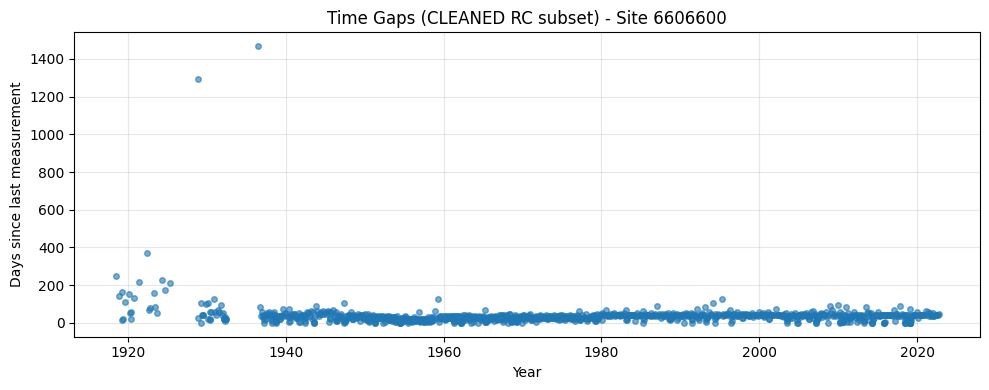

In [6]:
# ==============================================================================
# 4. TIME DEPENDENCY CHECK (CLEANED DATA USED FOR RC)
# Merges obs_df_filtered back onto timestamps from site_df
# ==============================================================================

site_df_time = site_df.copy()
site_df_time["measurement_dt"] = pd.to_datetime(site_df_time["measurement_dt"], errors="coerce")

# Merge cleaned (Q,H) back with measurement_dt by matching on discharge & stage
# (Assumes discharge_m3s + stage_m pairs are stable identifiers in your dataset)
df_clean_time = site_df_time.merge(
    obs_df_filtered,
    on=["discharge_m3s", "stage_m"],
    how="inner"
).dropna(subset=["measurement_dt"]).sort_values("measurement_dt").reset_index(drop=True)

df_clean_time["time_gap"] = df_clean_time["measurement_dt"].diff()
df_clean_time["gap_minutes"] = df_clean_time["time_gap"].dt.total_seconds() / 60
gaps_days = df_clean_time["gap_minutes"] / (60 * 24)

print(f"Analysis for Site: {TARGET_SITE}")
print(f"Total observations (cleaned RC subset): {len(df_clean_time)}")
print("-" * 35)
print(f"Minimum gap: {gaps_days.min():.4f} days ({df_clean_time['gap_minutes'].min():.2f} minutes)")
print(f"Median gap:  {gaps_days.median():.2f} days")
print(f"Mean gap:    {gaps_days.mean():.2f} days")
print("-" * 35)

plt.figure(figsize=(10, 4))
plt.plot(df_clean_time["measurement_dt"], gaps_days, "o", markersize=4, alpha=0.6)
plt.title(f"Time Gaps (CLEANED RC subset) - Site {TARGET_SITE}")
plt.ylabel("Days since last measurement")
plt.xlabel("Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# ==============================================================================
# 5. DATA CLEANING: COLLAPSING DUPLICATES AND DAILY RESAMPLING
# ==============================================================================

# 1. Ensure measurement_dt is in datetime format
ifmha_subset_stat['measurement_dt'] = pd.to_datetime(ifmha_subset_stat['measurement_dt'])

# 2. Create a 'date' column (ignoring hours/minutes/seconds)
# to group all measurements taken on the same calendar day.
ifmha_subset_stat['measurement_date'] = ifmha_subset_stat['measurement_dt'].dt.date

# 3. Perform the aggregation:
# We group by site_no AND date to ensure we don't mix different river stations.
# We average the discharge and stage for entries on the same day.
cleaned_ifmha = ifmha_subset_stat.groupby(['site_no', 'measurement_date']).agg({
    'discharge_m3s': 'mean',
    'stage_m': 'mean',
    # Keep other useful metadata by taking the 'first' entry found
    'COMID': 'first',
    'station_nm': 'first',
    'LatSite': 'first',
    'LonSite': 'first'
}).reset_index()

# 4. Sort by site and date to maintain time-series integrity
cleaned_ifmha = cleaned_ifmha.sort_values(['site_no', 'measurement_date'])

# --- Verify Results ---
print(f"Original Row Count: {len(ifmha_subset_stat)}")
print(f"Cleaned Row Count:  {len(cleaned_ifmha)}")
print(f"Rows Removed (Duplicates/Sub-Daily): {len(ifmha_subset_stat) - len(cleaned_ifmha)}")

# Check a specific site (e.g., your previous example)
site_check = cleaned_ifmha[cleaned_ifmha['site_no'] == '6606600']
print(f"\nSite 6606600 now has {len(site_check)} daily observations.")
display(site_check.head())

Original Row Count: 2064782
Cleaned Row Count:  1972281
Rows Removed (Duplicates/Sub-Daily): 92501

Site 6606600 now has 1084 daily observations.


,site_no,measurement_date,discharge_m3s,stage_m,COMID,station_nm,LatSite,LonSite
1467204,6606600,1917-09-22,4.728911,0.908304,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
1467205,6606600,1918-05-28,25.428515,1.591056,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
1467206,6606600,1918-10-18,3.313069,0.743712,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
1467207,6606600,1919-03-29,59.465347,2.490216,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
1467208,6606600,1919-04-12,78.437625,2.837688,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611


In [9]:


# ==============================================================================
# PREP: Extract single-site daily series
# ==============================================================================

TARGET_SITE = "6606600"

df_site = cleaned_ifmha.loc[
    cleaned_ifmha["site_no"].astype(str) == str(TARGET_SITE)
].copy()

df_site = df_site.sort_values("measurement_date").reset_index(drop=True)

# Drop missing values just in case
df_site = df_site.dropna(subset=["discharge_m3s", "stage_m"])

print(f"Site {TARGET_SITE} daily observations:", len(df_site))
df_site.head()


Site 6606600 daily observations: 1083


,site_no,measurement_date,discharge_m3s,stage_m,COMID,station_nm,LatSite,LonSite
0,6606600,1917-09-22,4.728911,0.908304,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
1,6606600,1918-05-28,25.428515,1.591056,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
2,6606600,1918-10-18,3.313069,0.743712,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
3,6606600,1919-03-29,59.465347,2.490216,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611
4,6606600,1919-04-12,78.437625,2.837688,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611


--- Temporal Analysis for Cleaned Site 6606600 ---
Minimum time gap: 1.0 day(s)
Median time gap:  32.0 days
Maximum time gap: 1468.0 days
--------------------------------------------------


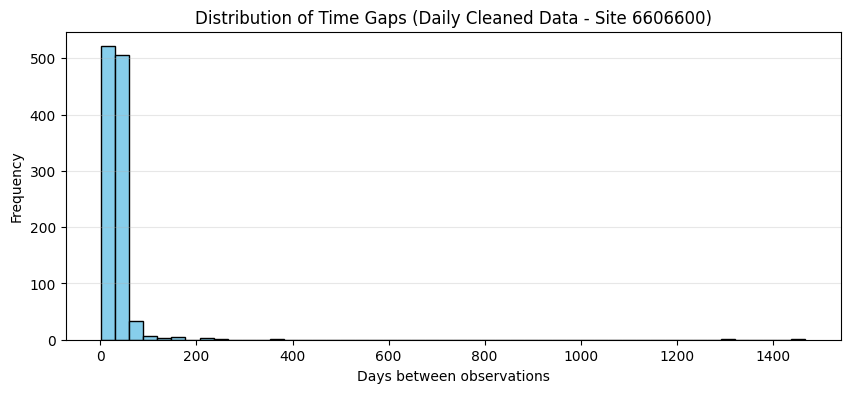

In [10]:
# ==============================================================================
# 8. POST-CLEANING TEMPORAL ANALYSIS
# ==============================================================================

# 1. Ensure measurement_date is a datetime object for calculations
df_site['measurement_date'] = pd.to_datetime(df_site['measurement_date'])

# 2. Sort chronologically
df_site = df_site.sort_values('measurement_date')

# 3. Calculate the difference between successive daily observations
df_site['day_diff'] = df_site['measurement_date'].diff().dt.days

# 4. Extract Statistics
min_gap_days = df_site['day_diff'].min()
median_gap_days = df_site['day_diff'].median()
max_gap_days = df_site['day_diff'].max()

print(f"--- Temporal Analysis for Cleaned Site {TARGET_SITE} ---")
print(f"Minimum time gap: {min_gap_days} day(s)")
print(f"Median time gap:  {median_gap_days} days")
print(f"Maximum time gap: {max_gap_days} days")
print("-" * 50)

# 5. Visual Check: Distribution of Gaps
plt.figure(figsize=(10, 4))
plt.hist(df_site['day_diff'].dropna(), bins=50, color='skyblue', edgecolor='black')
plt.title(f"Distribution of Time Gaps (Daily Cleaned Data - Site {TARGET_SITE})")
plt.xlabel("Days between observations")
plt.ylabel("Frequency")
plt.grid(axis='y', alpha=0.3)
plt.show()

In [11]:
# ==============================================================================
# 9. SMART TEMPORAL FILTERING (MINIMUM GAP ENFORCEMENT)
# ==============================================================================

# --- Configuration ---
MIN_GAP_DAYS =3  # The minimum difference you want between observations

# 1. Ensure data is sorted by date
df_site = df_site.sort_values("measurement_date").reset_index(drop=True)

# 2. Logic: Only keep a row if it's far enough from the last 'accepted' row
kept_indices = []
if not df_site.empty:
    last_kept_date = df_site['measurement_date'].iloc[0]
    kept_indices.append(df_site.index[0])

    for i in range(1, len(df_site)):
        current_date = df_site['measurement_date'].iloc[i]
        if (current_date - last_kept_date).days >= MIN_GAP_DAYS:
            kept_indices.append(i)
            last_kept_date = current_date

# 3. Apply the filter while keeping the same variable name
df_site = df_site.loc[kept_indices].copy()

# 4. Re-calculate the day_diff for verification
df_site['day_diff'] = df_site['measurement_date'].diff().dt.days

# --- Verification Output ---
print(f"Filtering complete: Minimum gap of {MIN_GAP_DAYS} days enforced.")
print(f"Remaining observations: {len(df_site)}")
print(f"New Minimum time gap: {df_site['day_diff'].min()} days")
print(f"New Median time gap:  {df_site['day_diff'].median():.1f} days")
print("-" * 50)

display(df_site.head())

Filtering complete: Minimum gap of 3 days enforced.
Remaining observations: 1051
New Minimum time gap: 3.0 days
New Median time gap:  33.0 days
--------------------------------------------------


,site_no,measurement_date,discharge_m3s,stage_m,COMID,station_nm,LatSite,LonSite,day_diff
0,6606600,1917-09-22,4.728911,0.908304,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611,NaN
1,6606600,1918-05-28,25.428515,1.591056,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611,248.0
2,6606600,1918-10-18,3.313069,0.743712,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611,143.0
3,6606600,1919-03-29,59.465347,2.490216,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611,162.0
4,6606600,1919-04-12,78.437625,2.837688,14624658.0,"Little Sioux River at Correctionville, IA",42.482222,-95.792611,14.0


In [ ]:
# ==============================================================================
# 10. PHYSICAL PLAUSIBILITY FILTER
# ==============================================================================
# Applied identically at all three case-study sites (see PROJECT_METHODOLOGY.md
# Section 5, Step 3): a non-positive discharge or stage is a sensor/data-entry
# error, and a stage >= 20 m is outside the physically plausible range for
# these rivers. No site-specific discharge cap or year cutoff is applied here.

# --- Configuration ---
MAX_STAGE_THRESHOLD = 20.0  # Physically implausible stage in meters

# 1. Identify implausible rows
is_physical_outlier = (
    (df_site['discharge_m3s'] <= 0) |
    (df_site['stage_m'] <= 0) |
    (df_site['stage_m'] >= MAX_STAGE_THRESHOLD)
)

# 2. Split into Inliers and Outliers
df_outliers = df_site[is_physical_outlier].copy()
df_inliers = df_site[~is_physical_outlier].copy()

# 3. Update df_site to ONLY contain valid data
df_site = df_inliers.copy()

# 4. Verification Output
print(f"--- Physical Plausibility Filter: Site {TARGET_SITE} ---")
print(f"Removed (Q<=0, H<=0, or H>={MAX_STAGE_THRESHOLD}m): {len(df_outliers)}")
print(f"Observations remaining for analysis: {len(df_site)}")
print("-" * 50)

# --- Visualization ---
plt.figure(figsize=(10, 6))

plt.scatter(df_inliers["discharge_m3s"], df_inliers["stage_m"],
            s=20, alpha=0.5, color="royalblue", label="Valid Observations")

if len(df_outliers) > 0:
    plt.scatter(df_outliers["discharge_m3s"], df_outliers["stage_m"],
                s=80, marker="x", color="black", label="Removed (implausible)")

plt.axhline(MAX_STAGE_THRESHOLD, color='red', linestyle='--', alpha=0.5, label="Stage threshold")

plt.title(f"Physical Plausibility Check - Site {TARGET_SITE}")
plt.xlabel("Discharge (m³/s)")
plt.ylabel("Stage (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [12]:
cleaned_ifmha = df_site

In [13]:
# ==============================================================================
# 7. GENERATE SITE SUMMARY TABLE FOR PAPER
# ==============================================================================

import scipy.stats as stats

# 1. Identify the site (Ensure TARGET_SITE is set)
# We use 'cleaned_ifmha' for hydraulic stats and 'site_df' for static metadata
target_cleaned = cleaned_ifmha[cleaned_ifmha['site_no'] == TARGET_SITE]
target_raw = ifmha_subset_stat[ifmha_subset_stat['site_no'] == TARGET_SITE]

if not target_cleaned.empty:
    # 2. Extract Metadata (Static values)
    river_name = target_raw['station_nm'].iloc[0]
    location = target_raw['STATE'].iloc[0]
    site_id = TARGET_SITE
    stream_order = target_raw['StreamOrde'].iloc[0]
    drainage_area = target_raw['DASqKm'].iloc[0]

    # 3. Calculate Hydraulic Stats (Cleaned Daily Data)
    avg_q = target_cleaned['discharge_m3s'].mean()
    min_q = target_cleaned['discharge_m3s'].min()
    max_q = target_cleaned['discharge_m3s'].max()

    avg_h = target_cleaned['stage_m'].mean()
    min_h = target_cleaned['stage_m'].min()
    max_h = target_cleaned['stage_m'].max()

    # 4. Calculate Dependencies (Rank-based)
    k_tau, _ = stats.kendalltau(target_cleaned['discharge_m3s'], target_cleaned['stage_m'], nan_policy='omit')
    s_rho, _ = stats.spearmanr(target_cleaned['discharge_m3s'], target_cleaned['stage_m'], nan_policy='omit')

    # 5. Compile into a Dictionary/DataFrame
    summary_data = {
        "River/Station": river_name,
        "State": location,
        "USGS Site No.": site_id,
        "Stream Order": int(stream_order) if not np.isnan(stream_order) else "N/A",
        "Drainage Area (km²)": round(drainage_area, 2),
        "Discharge (Avg/Min/Max)": f"{avg_q:.2f} / {min_q:.2f} / {max_q:.2f}",
        "Stage (Avg/Min/Max)": f"{avg_h:.2f} / {min_h:.2f} / {max_h:.2f}",
        "Kendall’s τ": round(k_tau, 3),
        "Spearman’s ρ": round(s_rho, 3)
    }

    # Convert to DataFrame for a nice display
    table_df = pd.DataFrame([summary_data])

    print(f"### Study Case Summary: Site {TARGET_SITE} ###")
    display(table_df)
else:
    print(f"No cleaned data found for Site {TARGET_SITE}. Please run the cleaning cell first.")

### Study Case Summary: Site 6606600 ###


,River/Station,State,USGS Site No.,Stream Order,Drainage Area (km²),Discharge (Avg/Min/Max),Stage (Avg/Min/Max),Kendall’s τ,Spearman’s ρ
0,"Little Sioux River at Correctionville, IA",IA,6606600,6,6475.0,41.43 / 0.14 / 700.84,2.33 / 0.58 / 7.70,0.688,0.867


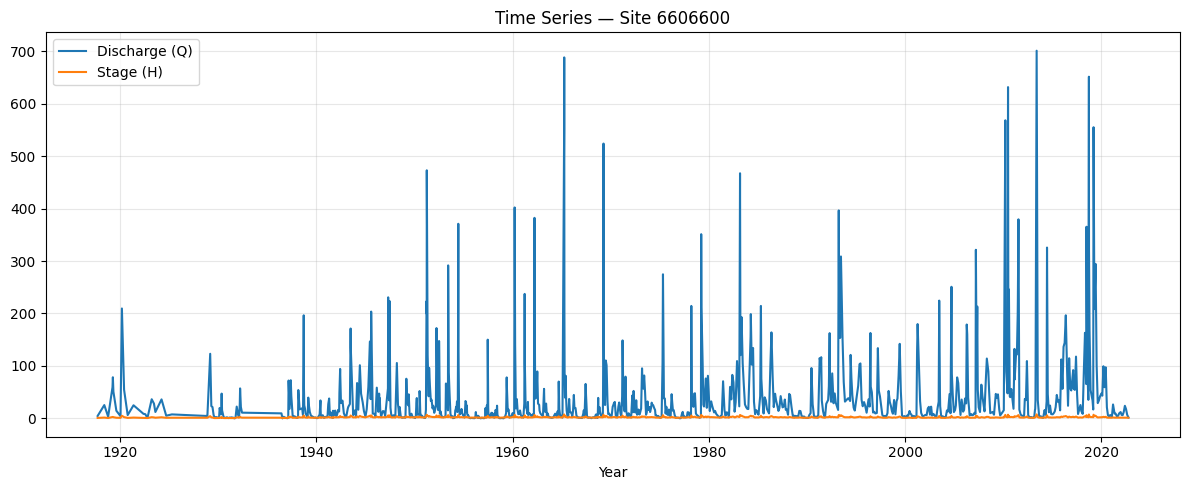

In [14]:
plt.figure(figsize=(12,5))
plt.plot(df_site["measurement_date"], df_site["discharge_m3s"], label="Discharge (Q)")
plt.plot(df_site["measurement_date"], df_site["stage_m"], label="Stage (H)")
plt.legend()
plt.title(f"Time Series — Site {TARGET_SITE}")
plt.xlabel("Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


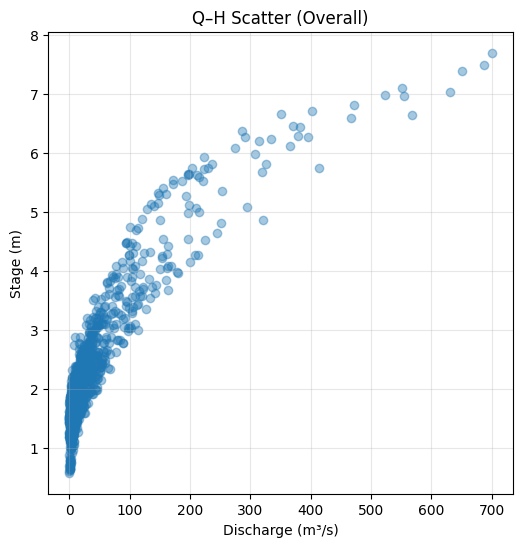

In [15]:
plt.figure(figsize=(6,6))
plt.scatter(df_site["discharge_m3s"], df_site["stage_m"], alpha=0.4)
plt.xlabel("Discharge (m³/s)")
plt.ylabel("Stage (m)")
plt.title("Q–H Scatter (Overall)")
plt.grid(alpha=0.3)
plt.show()


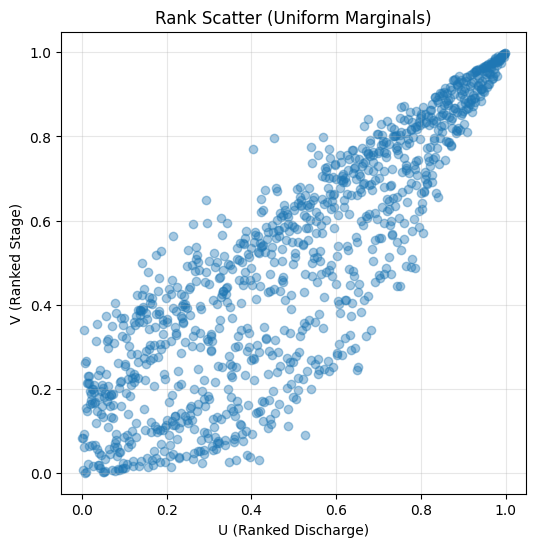

In [16]:
from scipy.stats import rankdata

Q = df_site["discharge_m3s"].values
H = df_site["stage_m"].values

u = rankdata(Q) / (len(Q) + 1)
v = rankdata(H) / (len(H) + 1)

plt.figure(figsize=(6,6))
plt.scatter(u, v, alpha=0.4)
plt.xlabel("U (Ranked Discharge)")
plt.ylabel("V (Ranked Stage)")
plt.title("Rank Scatter (Uniform Marginals)")
plt.grid(alpha=0.3)
plt.show()


In [17]:
from scipy.stats import kendalltau, spearmanr

tau, _ = kendalltau(Q, H)
rho, _ = spearmanr(Q, H)

print("Kendall's tau:", tau)
print("Spearman's rho:", rho)


Kendall's tau: 0.6881968277682473
Spearman's rho: 0.8673800359848143


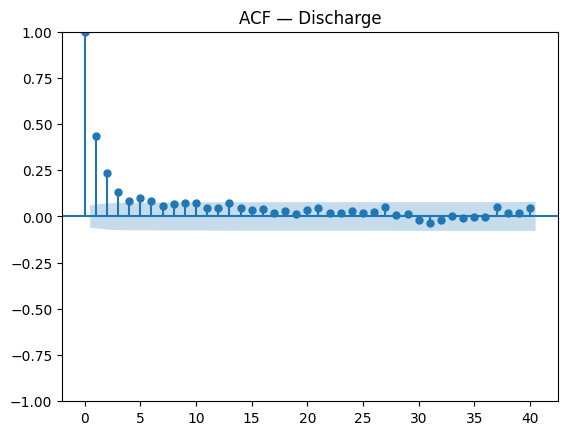

In [18]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(df_site["discharge_m3s"], lags=40)
plt.title("ACF — Discharge")
plt.show()


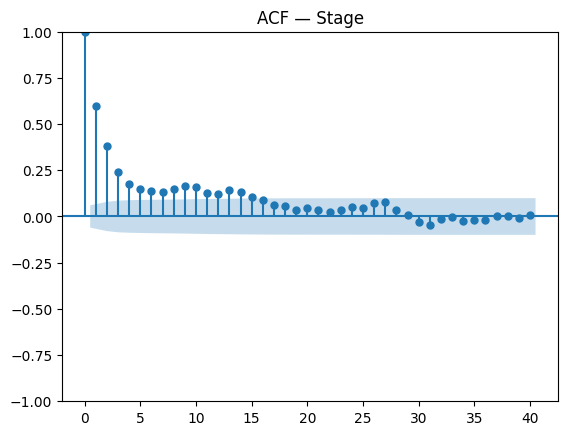

In [19]:
plot_acf(df_site["stage_m"], lags=40)
plt.title("ACF — Stage")
plt.show()


✅ Dependencies found. Proceeding with Bankfull Analysis (DAILY data)...
   Target Site: 6606600
   Target COMID: 14624658
   Daily observations available: 1051

  BANKFULL THRESHOLD ANALYSIS (DAILY) - Site 6606600
1) Geomorphic input (external):
   Bankfull depth (bnk_depth): 4.387 m
2) Hydraulic translation (rating curve):
   Assumed bankfull stage H_bf: 4.387 m
   Computed bankfull discharge Q_bf: 133.684 m³/s

✅ Partitioning complete (DAILY data).
   Threshold Q_bf: 133.684 m³/s
   High-flow days identified: 81 / 1051
   Plot saved to 'bankfull_partitioning_daily.png'


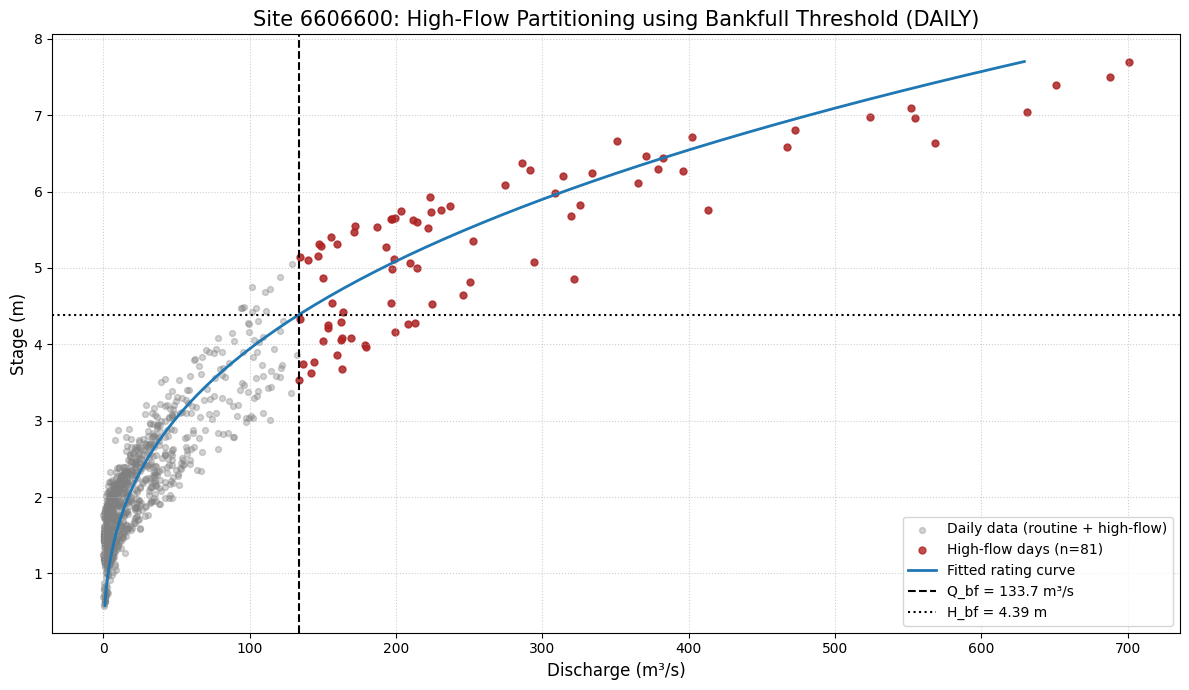

In [20]:
# ==============================================================================
# 5A. BANKFULL THRESHOLD & HIGH-FLOW PARTITIONING (USING cleaned_ifmha DAILY DATA)
# ==============================================================================

# --- 0. Dependencies Check ---
required = ["C_fit", "n_fit", "H0_fit", "rating_curve_model", "cleaned_ifmha", "TARGET_SITE"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing dependencies: {missing}. Run the rating-curve cell and daily-aggregation cell first.")

print("✅ Dependencies found. Proceeding with Bankfull Analysis (DAILY data)...")

# --- 1. Configuration ---
BANKFULL_DATA_PATH = "/content/drive/MyDrive/IFMHA/Bankfull_Meanflow_CONUS.txt"

# --- 2. Extract DAILY site data from cleaned_ifmha ---
df_daily_site = cleaned_ifmha.loc[
    cleaned_ifmha["site_no"].astype(str) == str(TARGET_SITE)
].copy()

if df_daily_site.empty:
    raise ValueError(f"No daily data found in cleaned_ifmha for site {TARGET_SITE}.")

# Ensure datetime and sort
df_daily_site["measurement_date"] = pd.to_datetime(df_daily_site["measurement_date"], errors="coerce")
df_daily_site = df_daily_site.dropna(subset=["measurement_date", "discharge_m3s", "stage_m"]).copy()
df_daily_site = df_daily_site.sort_values("measurement_date").reset_index(drop=True)

# Pull COMID (should be constant per site)
try:
    SITE_COMID = str(int(df_daily_site["COMID"].iloc[0]))
except Exception as e:
    raise ValueError(f"Could not extract a valid COMID for site {TARGET_SITE}. Error: {e}")

print(f"   Target Site: {TARGET_SITE}")
print(f"   Target COMID: {SITE_COMID}")
print(f"   Daily observations available: {len(df_daily_site)}")

# --- 3. Load external bankfull geomorphology file and lookup bnk_depth ---
try:
    bankfull_conus_df = pd.read_csv(BANKFULL_DATA_PATH, usecols=["COMID", "bnk_depth"], low_memory=False)
except FileNotFoundError:
    raise FileNotFoundError(f"Could not load external bankfull file: {BANKFULL_DATA_PATH}")

site_bankfull_geo = bankfull_conus_df.loc[bankfull_conus_df["COMID"].astype(str) == SITE_COMID].copy()
if site_bankfull_geo.empty:
    raise ValueError(f"No geomorphic record found for COMID {SITE_COMID} in bankfull dataset.")

bankfull_depth_m_external = float(site_bankfull_geo.iloc[0]["bnk_depth"])

# --- 4. Translate Bankfull Depth -> Bankfull Discharge using fitted RC ---
# Assumption: bankfull depth approximates bankfull stage (same vertical datum).
H_bf = bankfull_depth_m_external

Q_bf = float(rating_curve_model(H_bf, C_fit, n_fit, H0_fit))

print("\n" + "="*55)
print(f"  BANKFULL THRESHOLD ANALYSIS (DAILY) - Site {TARGET_SITE}")
print("="*55)
print("1) Geomorphic input (external):")
print(f"   Bankfull depth (bnk_depth): {bankfull_depth_m_external:.3f} m")
print("2) Hydraulic translation (rating curve):")
print(f"   Assumed bankfull stage H_bf: {H_bf:.3f} m")
print(f"   Computed bankfull discharge Q_bf: {Q_bf:.3f} m³/s")
print("="*55 + "\n")

# --- 5. Partition DAILY data into high-flow events ---
df_high_flow_daily = df_daily_site.loc[df_daily_site["discharge_m3s"] >= Q_bf].copy()

print("✅ Partitioning complete (DAILY data).")
print(f"   Threshold Q_bf: {Q_bf:.3f} m³/s")
print(f"   High-flow days identified: {len(df_high_flow_daily)} / {len(df_daily_site)}")

# --- 6. Visualization (Q–H with threshold & fitted RC) ---
# Build a stage grid for RC line (use daily H range for plotting)
H_grid_plot = np.linspace(df_daily_site["stage_m"].min(), df_daily_site["stage_m"].max(), 200)
Q_rc_plot = rating_curve_model(H_grid_plot, C_fit, n_fit, H0_fit)

plt.figure(figsize=(12, 7))

# Daily points
plt.scatter(df_daily_site["discharge_m3s"], df_daily_site["stage_m"],
            s=18, alpha=0.35, color="gray", label="Daily data (routine + high-flow)")

# High-flow daily points
plt.scatter(df_high_flow_daily["discharge_m3s"], df_high_flow_daily["stage_m"],
            s=25, alpha=0.8, color="firebrick", label=f"High-flow days (n={len(df_high_flow_daily)})")

# Rating curve line (Q as x, H as y)
plt.plot(Q_rc_plot, H_grid_plot, lw=2, label="Fitted rating curve")

# Threshold lines
plt.axvline(x=Q_bf, color="black", linestyle="--", label=f"Q_bf = {Q_bf:.1f} m³/s")
plt.axhline(y=H_bf, color="black", linestyle=":", label=f"H_bf = {H_bf:.2f} m")

plt.title(f"Site {TARGET_SITE}: High-Flow Partitioning using Bankfull Threshold (DAILY)", fontsize=15)
plt.xlabel("Discharge (m³/s)", fontsize=12)
plt.ylabel("Stage (m)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()

plt.savefig("bankfull_partitioning_daily.png", dpi=200)
print("   Plot saved to 'bankfull_partitioning_daily.png'")
plt.show()


✅ Found df_daily_site (size: 1051). Proceeding (DAILY)...
New threshold set to Q = 47.29 m³/s to capture ~top 220 daily points.
Found 221 daily observations at or above the threshold.
Saved plot to 'relaxed_threshold_daily_plot.png'


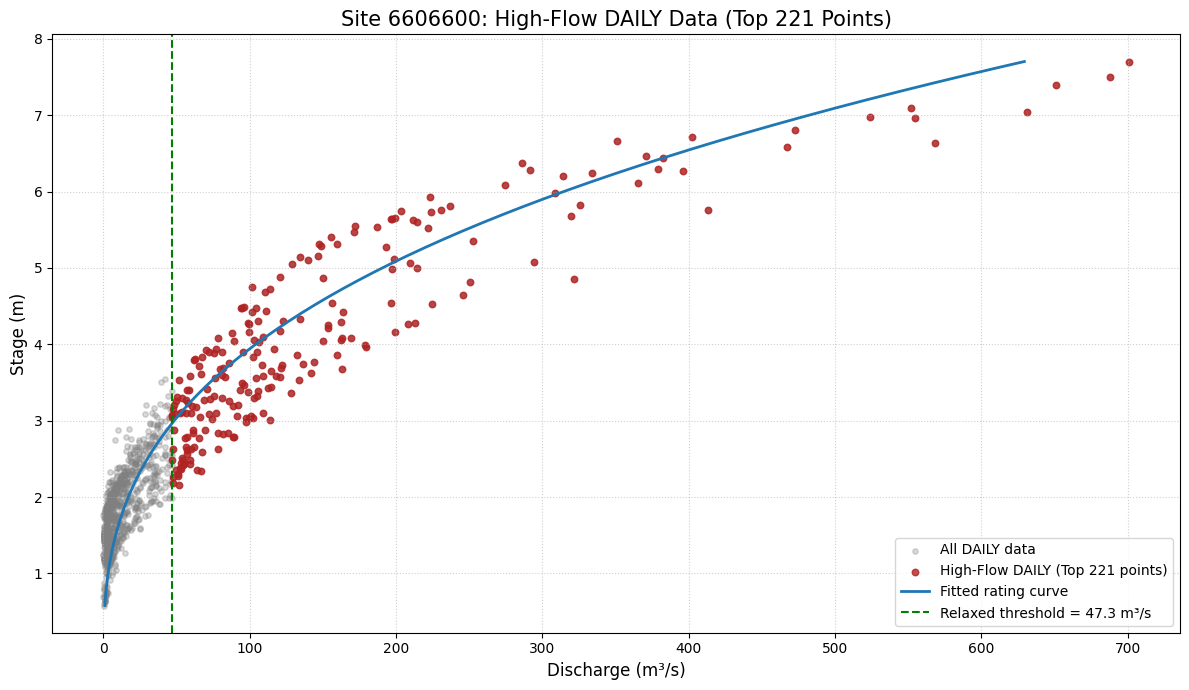

In [22]:
# ==============================================================================
# 6. ADJUST THRESHOLD FOR A FIXED NUMBER OF POINTS (DAILY DATA COMPATIBLE)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Configuration ---
N_POINTS_DESIRED = 220

# --- 2. Dependencies Check ---
required = ["df_daily_site", "TARGET_SITE", "C_fit", "n_fit", "H0_fit", "rating_curve_model"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing dependencies: {missing}. Run the daily bankfull cell first.")

print(f"✅ Found df_daily_site (size: {len(df_daily_site)}). Proceeding (DAILY)...")

# --- 3. Calculate New Threshold based on DAILY discharge ---
if len(df_daily_site) < N_POINTS_DESIRED:
    print(f"⚠️ Warning: Desired points ({N_POINTS_DESIRED}) exceeds available daily data ({len(df_daily_site)}).")
    final_threshold = df_daily_site["discharge_m3s"].min()
else:
    final_threshold = df_daily_site["discharge_m3s"].nlargest(N_POINTS_DESIRED).iloc[-1]

print(f"New threshold set to Q = {final_threshold:.2f} m³/s to capture ~top {N_POINTS_DESIRED} daily points.")

# --- 4. Create High-Flow DAILY Subset (Top N) ---
# Note: ties may yield slightly more than N_POINTS_DESIRED
df_high_flow_daily_relaxed = df_daily_site.loc[df_daily_site["discharge_m3s"] >= final_threshold].copy()
print(f"Found {len(df_high_flow_daily_relaxed)} daily observations at or above the threshold.")

# --- 5. Visualization ---
# Build RC curve for plotting over the DAILY stage range
H_grid_plot = np.linspace(df_daily_site["stage_m"].min(), df_daily_site["stage_m"].max(), 200)
Q_rc_plot = rating_curve_model(H_grid_plot, C_fit, n_fit, H0_fit)

plt.figure(figsize=(12, 7))

# All daily points
plt.scatter(df_daily_site["discharge_m3s"], df_daily_site["stage_m"],
            s=15, alpha=0.3, color="gray", label="All DAILY data")

# Top-N daily points
plt.scatter(df_high_flow_daily_relaxed["discharge_m3s"], df_high_flow_daily_relaxed["stage_m"],
            s=22, alpha=0.8, color="firebrick",
            label=f"High-Flow DAILY (Top {len(df_high_flow_daily_relaxed)} points)")

# Rating curve line (Q vs H)
plt.plot(Q_rc_plot, H_grid_plot, lw=2, label="Fitted rating curve")

# Threshold line
plt.axvline(x=final_threshold, color="green", linestyle="--",
            label=f"Relaxed threshold = {final_threshold:.1f} m³/s")

plt.title(f"Site {TARGET_SITE}: High-Flow DAILY Data (Top {len(df_high_flow_daily_relaxed)} Points)", fontsize=15)
plt.xlabel("Discharge (m³/s)", fontsize=12)
plt.ylabel("Stage (m)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()

plt.savefig("relaxed_threshold_daily_plot.png", dpi=200)
print("Saved plot to 'relaxed_threshold_daily_plot.png'")
plt.show()


✅ Found DAILY high-flow dataset with 221 points. Ready for cleaning.

Calculating residuals against the fitted rating curve (DAILY high-flow)...
Mean |residual|: 0.478 m
Std  |residual|: 0.284 m
Outlier threshold (mean + 3σ): 1.330 m
Identified and removed 0 outliers.
Final cleaned DAILY high-flow dataset size: 221 points.


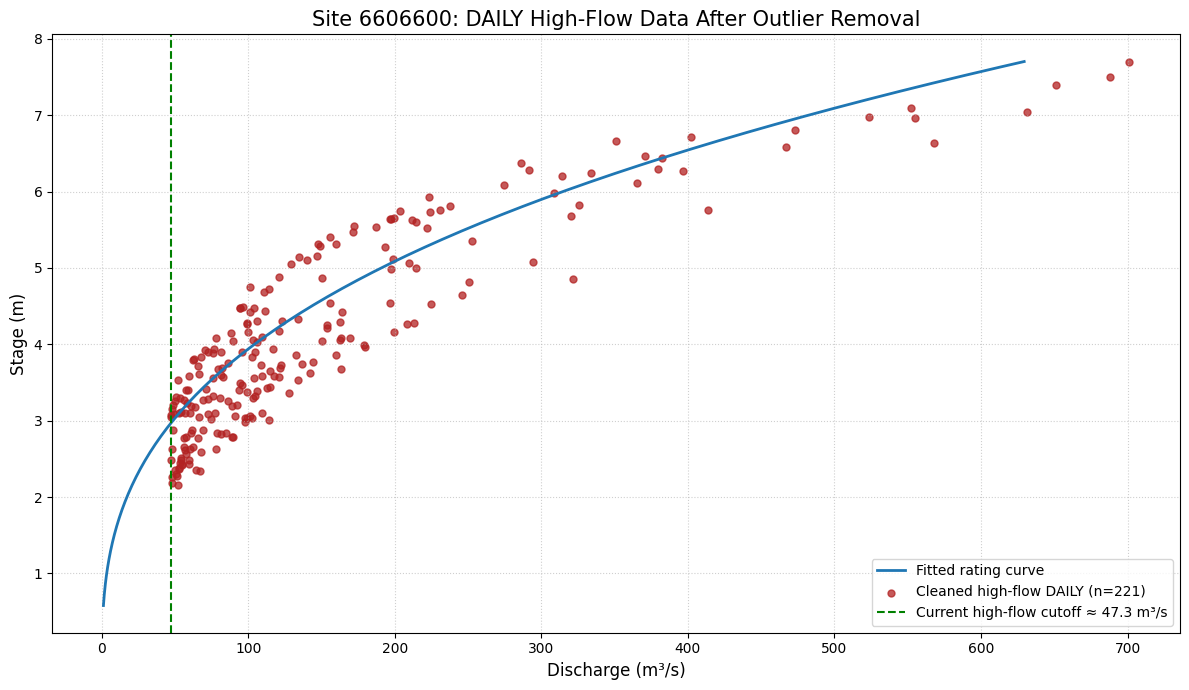

In [23]:
# ==============================================================================
# 5C. OUTLIER REMOVAL FROM THE HIGH-FLOW DATASET (DAILY COMPATIBLE)
# ==============================================================================
# Cleans the final DAILY high-flow dataset by removing points that are far from
# the central trend defined by the fitted rating curve (RC).
#
# Outliers are identified based on absolute stage residuals:
# |H_obs - H_pred(Q)| > mean(residual) + 3*std(residual)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Dependencies Check ---
required = ["df_high_flow_daily_relaxed", "df_daily_site", "C_fit", "n_fit", "H0_fit", "rating_curve_model", "TARGET_SITE"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing dependencies: {missing}. Run the DAILY bankfull + top-N selection cells first.")

print(f"✅ Found DAILY high-flow dataset with {len(df_high_flow_daily_relaxed)} points. Ready for cleaning.")

# --- 2. Define the Inverse Rating Curve Function ---
# Q = C*(H-H0)^n  ->  H = (Q/C)^(1/n) + H0
def predict_stage_from_discharge(Q, C, n, H0):
    Q_safe = np.maximum(np.asarray(Q, dtype=float), 1e-9)
    return (Q_safe / C) ** (1.0 / n) + H0

# --- 3. Calculate Residuals on DAILY High-Flow Data ---
predicted_stage = predict_stage_from_discharge(
    df_high_flow_daily_relaxed["discharge_m3s"].values, C_fit, n_fit, H0_fit
)

residuals = np.abs(df_high_flow_daily_relaxed["stage_m"].values - predicted_stage)

# --- 4. Define Outlier Threshold and Filter ---
residual_mean = residuals.mean()
residual_std = residuals.std(ddof=1)  # sample std
outlier_threshold = residual_mean + 3.0 * residual_std

print("\nCalculating residuals against the fitted rating curve (DAILY high-flow)...")
print(f"Mean |residual|: {residual_mean:.3f} m")
print(f"Std  |residual|: {residual_std:.3f} m")
print(f"Outlier threshold (mean + 3σ): {outlier_threshold:.3f} m")

is_outlier = residuals > outlier_threshold

df_inliers = df_high_flow_daily_relaxed.loc[~is_outlier].copy()
df_outliers = df_high_flow_daily_relaxed.loc[is_outlier].copy()

print(f"Identified and removed {len(df_outliers)} outliers.")
print(f"Final cleaned DAILY high-flow dataset size: {len(df_inliers)} points.")

# --- 5. Save Cleaned Output ---
df_high_flow_daily_cleaned = df_inliers.copy()

# Optional: overwrite for downstream compatibility
df_high_flow_daily_relaxed = df_high_flow_daily_cleaned

# --- 6. Visualization ---
# Rebuild RC curve for plotting over DAILY stage range
H_grid_plot = np.linspace(df_daily_site["stage_m"].min(), df_daily_site["stage_m"].max(), 200)
Q_rc_plot = rating_curve_model(H_grid_plot, C_fit, n_fit, H0_fit)

plt.figure(figsize=(12, 7))

# Rating curve line (Q vs H)
plt.plot(Q_rc_plot, H_grid_plot, lw=2, label="Fitted rating curve")

# Inliers
plt.scatter(df_inliers["discharge_m3s"], df_inliers["stage_m"],
            s=25, alpha=0.75, color="firebrick",
            label=f"Cleaned high-flow DAILY (n={len(df_inliers)})")

# Outliers
if len(df_outliers) > 0:
    plt.scatter(df_outliers["discharge_m3s"], df_outliers["stage_m"],
                s=90, marker="x", color="black", lw=2,
                label=f"Removed outliers (n={len(df_outliers)})", zorder=10)

# Threshold line for visual reference (the relaxed threshold you used)
final_threshold = df_high_flow_daily_cleaned["discharge_m3s"].min()
plt.axvline(x=final_threshold, color="green", linestyle="--",
            label=f"Current high-flow cutoff ≈ {final_threshold:.1f} m³/s")

plt.title(f"Site {TARGET_SITE}: DAILY High-Flow Data After Outlier Removal", fontsize=15)
plt.xlabel("Discharge (m³/s)", fontsize=12)
plt.ylabel("Stage (m)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [24]:
!pip install rasterio

In [25]:
!pip -q install copulas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.2 MB/s eta 0:00:00


Using 221 cleaned high-flow points for copula fitting.

--- Fitting Marginal Distributions ---
Best distribution for Discharge (x): GammaUnivariate
Best distribution for Stage (y): GammaUnivariate

--- Fitting and Scoring Copula Families (AIC/BIC corrected) ---

Copula comparison (sorted by BIC):
  family          ll  k         AIC         BIC
  gumbel  142.103021  1 -282.206043 -278.807880
   frank  134.538099  1 -267.076199 -263.678036
gaussian   12.834457  1  -23.668913  -20.270750
 clayton -260.239859  1  522.479719  525.877881

Best copula (by BIC): Gumbel

Fitted copula parameters (exposed):
  gaussian: {'theta': 0.8871373943109159, 'df': None}
  clayton: {'theta': np.float64(4.549195539638311), 'df': None}
  frank: {'theta': np.float64(11.169609053483551), 'df': None}
  gumbel: {'theta': np.float64(3.2745977698191555), 'df': None}

--- Generating Synthetic Data from each Copula ---


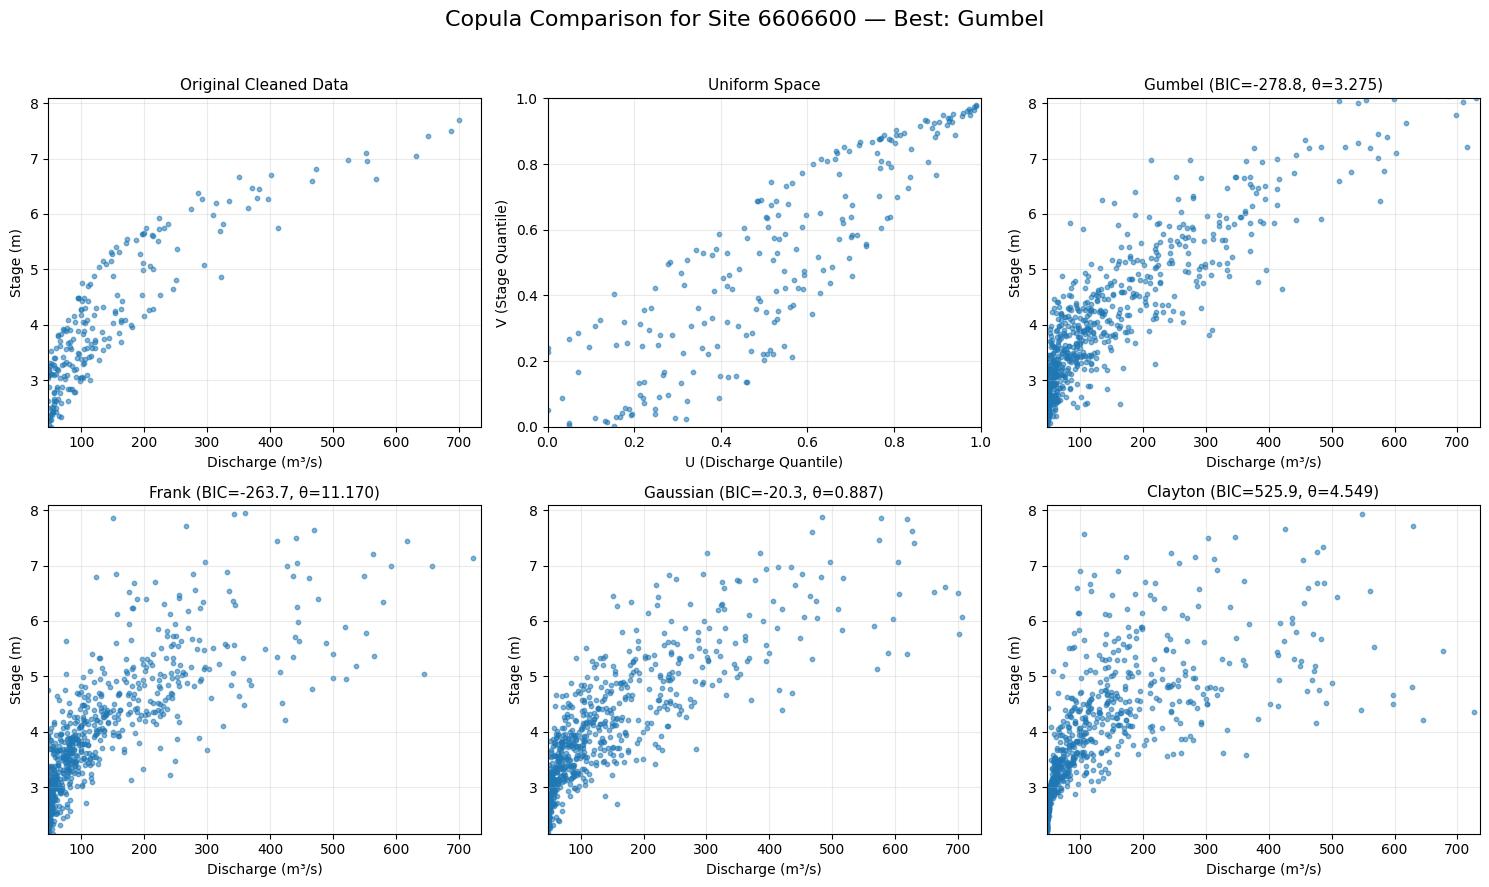

In [26]:
# ==============================================================================
# 8. COPULA ANALYSIS ON THE FINAL, CLEANED HIGH-FLOW DATA (ROBUST + COMPATIBLE)
# ==============================================================================
# - Uses df_high_flow from the previous outlier-cleaning cell (already cleaned)
# - Fits marginals (robust candidate set)
# - Fits candidate copulas (Gaussian, Student-t if available, Clayton, Frank, Gumbel)
# - Computes log-likelihood, AIC, BIC with correct parameter counts
# - Exposes fitted copula parameters for conditional sampling
# - Generates synthetic samples for visual checks
# ==============================================================================
# --- Bridge: Map the cleaned high-flow data to the expected variable name ---
df_high_flow = df_high_flow_daily_cleaned

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, kendalltau, multivariate_normal
from copulas.univariate import (
    Univariate, GammaUnivariate, TruncatedGaussian, GaussianUnivariate, StudentTUnivariate
)
from copulas.bivariate import Clayton, Frank, Gumbel

# Student-t copula (may or may not exist depending on copulas version)
try:
    from copulas.bivariate import StudentT as StudentTCopula
    _HAS_STUDENTT = True
except Exception:
    StudentTCopula = None
    _HAS_STUDENTT = False

SEED = 42
np.random.seed(SEED)
EPS = 1e-12
N_COLS_COPULA_GRID = 3
N_SYNTHETIC_POINTS = 700
POINT_ALPHA = 0.55
POINT_SIZE = 10

# --- Custom Gaussian Copula Class (validated logpdf) ---
class GaussianCopulaCompat:
    def __init__(self):
        self.rho = None

    @property
    def theta(self):
        return self.rho

    def fit(self, UV):
        tau = kendalltau(UV[:, 0], UV[:, 1]).correlation
        if tau is None or np.isnan(tau):
            tau = 0.0
        self.rho = float(np.sin(np.pi * tau / 2))

    def log_probability_density(self, UV):
        Z = norm.ppf(np.clip(UV, EPS, 1 - EPS))
        z1, z2 = Z[:, 0], Z[:, 1]
        r = float(self.rho) if self.rho is not None else 0.0
        cov = np.array([[1.0, r], [r, 1.0]])

        try:
            mvn_logpdf = multivariate_normal.logpdf(Z, mean=[0.0, 0.0], cov=cov, allow_singular=True)
            uni_logpdf = norm.logpdf(z1) + norm.logpdf(z2)
            log_c = mvn_logpdf - uni_logpdf
            # analytic fallback for any non-finite values
            bad = ~np.isfinite(log_c)
            if np.any(bad):
                omr2 = 1.0 - r**2
                analytic = (-0.5*np.log(omr2 + EPS)
                            -0.5*(z1**2 - 2*r*z1*z2 + z2**2)/omr2
                            +0.5*(z1**2 + z2**2))
                log_c[bad] = analytic[bad]
            return log_c
        except Exception:
            omr2 = 1.0 - r**2
            return (-0.5*np.log(omr2 + EPS)
                    -0.5*(z1**2 - 2*r*z1*z2 + z2**2)/omr2
                    +0.5*(z1**2 + z2**2))

    def sample(self, n_samples=None, num_samples=None):
        m = n_samples if n_samples is not None else num_samples
        if m is None:
            raise ValueError("Must provide either 'n_samples' or 'num_samples'.")
        r = float(self.rho) if self.rho is not None else 0.0
        cov = np.array([[1.0, r], [r, 1.0]])
        rng = np.random.default_rng(SEED)
        Z = rng.multivariate_normal([0.0, 0.0], cov, size=int(m))
        return norm.cdf(Z)

# --- Prepare Data for Copula Fitting ---
if "df_high_flow" not in globals():
    raise RuntimeError("ERROR: Expected 'df_high_flow'. Run the outlier-cleaning cell first (it overwrites df_high_flow).")

df_clean = df_high_flow.rename(columns={"discharge_m3s": "x", "stage_m": "y"}).copy()
df_clean = df_clean.dropna(subset=["x", "y"]).copy()

print(f"Using {len(df_clean)} cleaned high-flow points for copula fitting.")

if len(df_clean) < 20:
    raise ValueError(f"Not enough high-flow data points ({len(df_clean)}) for reliable copula fitting.")

# --- Fit Marginal Distributions and Transform Data ---
print("\n--- Fitting Marginal Distributions ---")

# Beta removed: it expects data in (0,1) and will misbehave for Q/H without rescaling
univariate_candidates = [GammaUnivariate, TruncatedGaussian, GaussianUnivariate, StudentTUnivariate]

ux = Univariate(candidates=univariate_candidates)
ux.fit(df_clean["x"].values)
print(f"Best distribution for Discharge (x): {ux.to_dict()['type'].split('.')[-1]}")

uy = Univariate(candidates=univariate_candidates)
uy.fit(df_clean["y"].values)
print(f"Best distribution for Stage (y): {uy.to_dict()['type'].split('.')[-1]}")

U = np.clip(ux.cdf(df_clean["x"].values), EPS, 1 - EPS)[:, None]
V = np.clip(uy.cdf(df_clean["y"].values), EPS, 1 - EPS)[:, None]
UV = np.hstack([U, V])

# --- Helper: parameter count per copula family ---
def copula_param_count(name):
    name = name.lower()
    if name == "gaussian":
        return 1  # rho
    if name in ("student", "studentt", "student-t"):
        return 2  # rho + df
    return 1  # clayton/frank/gumbel all have 1 parameter

# --- Fit Copula Models and Select Best (BIC) ---
print("\n--- Fitting and Scoring Copula Families (AIC/BIC corrected) ---")

def fit_and_score_copula(name, model, uv):
    model.fit(uv)
    logpdf_vals = np.asarray(model.log_probability_density(uv))
    if logpdf_vals.ndim == 0:
        logpdf_vals = np.full(len(uv), float(logpdf_vals))
    ll = float(np.sum(logpdf_vals))
    k = copula_param_count(name)
    n = len(uv)
    aic = 2 * k - 2 * ll
    bic = k * np.log(n) - 2 * ll
    return {"family": name, "ll": ll, "k": k, "AIC": aic, "BIC": bic}, model

rows_cop, models_cop = [], {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    copula_candidates = [("gaussian", GaussianCopulaCompat())]
    if _HAS_STUDENTT:
        copula_candidates.append(("student", StudentTCopula()))
    copula_candidates += [("clayton", Clayton()), ("frank", Frank()), ("gumbel", Gumbel())]

    for name, mdl in copula_candidates:
        try:
            row, fitted_model = fit_and_score_copula(name, mdl, UV)
            rows_cop.append(row)
            models_cop[name] = fitted_model
        except Exception as e:
            print(f"Fit failed for {name}: {e}")

score_cop_df = pd.DataFrame(rows_cop).sort_values("BIC").reset_index(drop=True)
if score_cop_df.empty:
    raise RuntimeError("No copula fits succeeded. Inspect data and model compatibility.")

best_name = score_cop_df.loc[0, "family"]
best_model = models_cop[best_name]

print("\nCopula comparison (sorted by BIC):")
print(score_cop_df.to_string(index=False))
print(f"\nBest copula (by BIC): {best_name.title()}")

# --- Extract fitted copula parameters for conditional sampling ---
fitted_copula_params = {}
for name, model in models_cop.items():
    theta = getattr(model, "theta", None)
    df_param = (getattr(model, "df", None)
                or getattr(model, "nu", None)
                or getattr(model, "degrees_of_freedom", None))
    fitted_copula_params[name] = {"theta": theta, "df": df_param}

print("\nFitted copula parameters (exposed):")
for k, v in fitted_copula_params.items():
    print(f"  {k}: {v}")

# --- Generate Synthetic Data for Visual Checks ---
print("\n--- Generating Synthetic Data from each Copula ---")

panels_to_plot = [
    ("Original Cleaned Data", df_clean["x"].values, df_clean["y"].values, "data"),
    ("Uniform Space", UV[:, 0], UV[:, 1], "uniform"),
]

for _, row in score_cop_df.iterrows():
    name = row["family"]
    model = models_cop[name]
    try:
        uv_synth = model.sample(n_samples=N_SYNTHETIC_POINTS)
    except TypeError:
        uv_synth = model.sample(num_samples=N_SYNTHETIC_POINTS)

    uv_synth = np.asarray(uv_synth)
    if uv_synth.ndim == 1 and uv_synth.size == 2 * N_SYNTHETIC_POINTS:
        uv_synth = uv_synth.reshape(N_SYNTHETIC_POINTS, 2)

    x_synth = ux.ppf(uv_synth[:, 0])
    y_synth = uy.ppf(uv_synth[:, 1])

    theta = getattr(model, "theta", None)
    theta_str = f", θ={theta:.3f}" if isinstance(theta, (float, int)) and np.isfinite(theta) else ""
    panels_to_plot.append((f"{name.title()} (BIC={row['BIC']:.1f}{theta_str})", x_synth, y_synth, "data"))

# --- Plot Grid ---
n_panels = len(panels_to_plot)
n_rows = int(np.ceil(n_panels / N_COLS_COPULA_GRID))

fig, axes = plt.subplots(n_rows, N_COLS_COPULA_GRID,
                         figsize=(N_COLS_COPULA_GRID * 5.0, n_rows * 4.5))
axes = np.atleast_1d(axes).ravel()

x_lims = (df_clean["x"].min(), df_clean["x"].max() * 1.05)
y_lims = (df_clean["y"].min(), df_clean["y"].max() * 1.05)

for ax, (title, x_data, y_data, mode) in zip(axes, panels_to_plot):
    ax.scatter(x_data, y_data, s=POINT_SIZE, alpha=POINT_ALPHA)
    if mode == "data":
        ax.set_xlim(x_lims)
        ax.set_ylim(y_lims)
        ax.set_xlabel("Discharge (m³/s)")
        ax.set_ylabel("Stage (m)")
    else:
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel("U (Discharge Quantile)")
        ax.set_ylabel("V (Stage Quantile)")
    ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.25)

for i in range(n_panels, len(axes)):
    axes[i].axis("off")

fig.suptitle(f"Copula Comparison for Site {TARGET_SITE} — Best: {best_name.title()}", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


Generating extended rating curve for comparison...
✅ Extended rating curve generated.

Generating 2x2 prediction plots (sorted by BIC)...


Predicting Gumbel Copula (BIC: -278.8):   0%|          | 0/90 [00:00<?, ?it/s]

/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


Predicting Frank Copula (BIC: -263.7):   0%|          | 0/90 [00:00<?, ?it/s]

Predicting Gaussian Copula (BIC: -20.3):   0%|          | 0/90 [00:00<?, ?it/s]

Predicting Clayton Copula (BIC: 525.9):   0%|          | 0/90 [00:00<?, ?it/s]

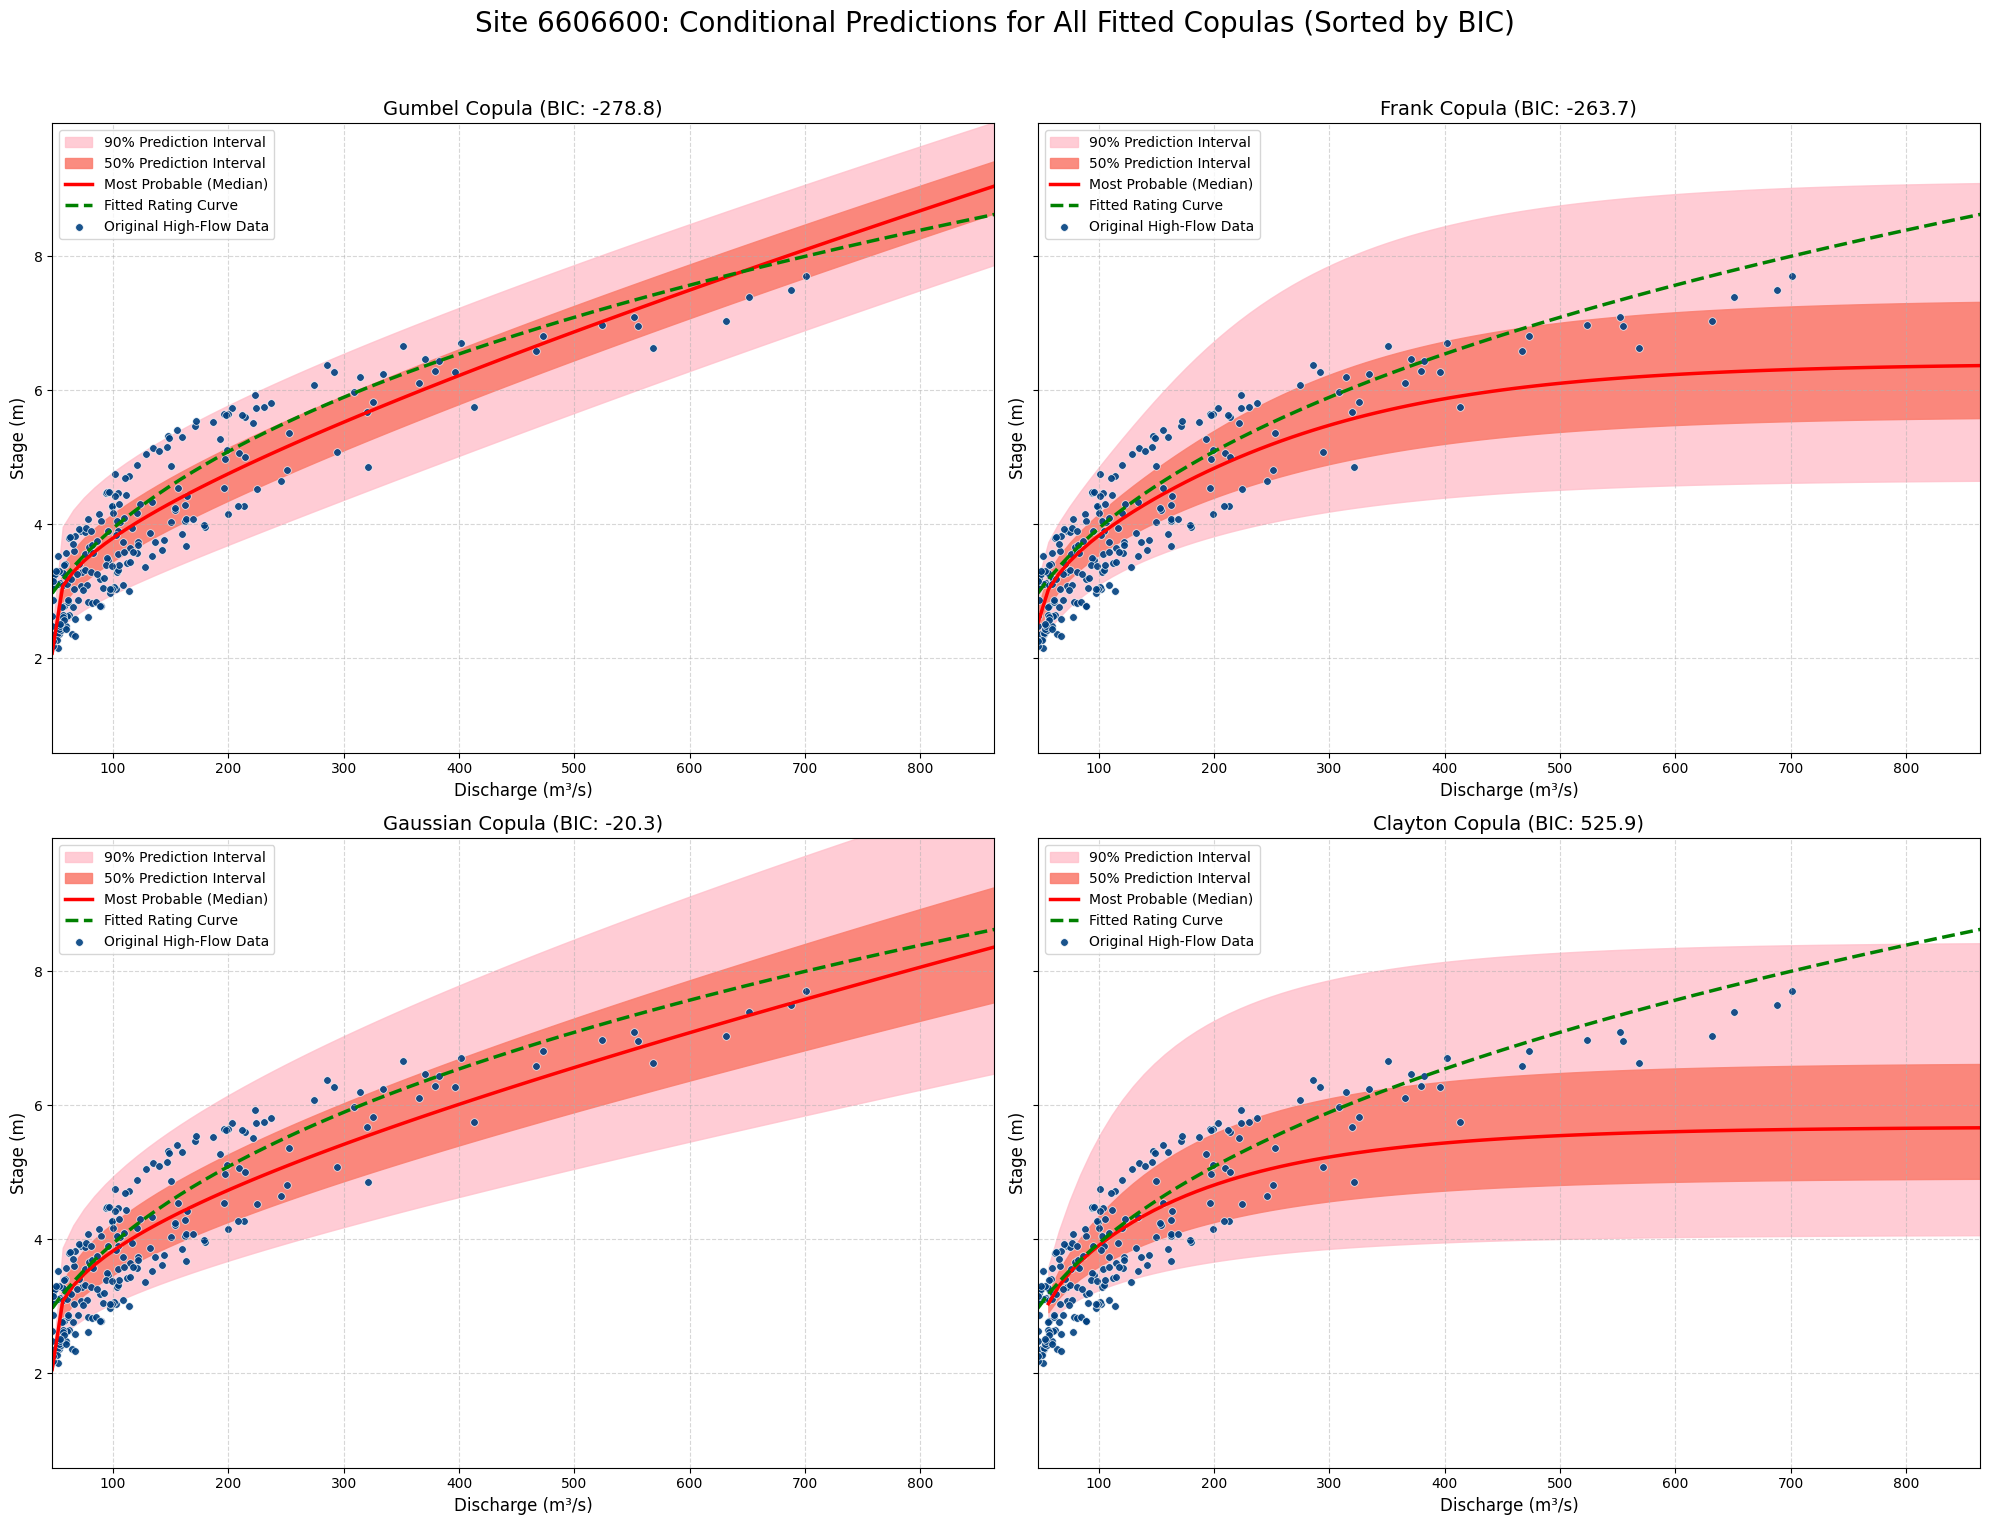

In [27]:
# ==============================================================================
# 9. CONDITIONAL PREDICTION PLOTS (FINAL, COMPATIBLE + ORIGINAL COLORS)
# ==============================================================================
# Purpose: Visualizes probabilistic rating curves via conditional densities
#          f(Stage | Discharge) = c(u,v) * f_y(y)
# where u = F_q(q), v = F_h(h), and c(u,v) is the copula density.
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# tqdm is optional
try:
    from tqdm.notebook import tqdm
    _HAS_TQDM = True
except Exception:
    tqdm = None
    _HAS_TQDM = False

EPS = 1e-12

# --- A. Dependency Check ---
required = ["ux", "uy", "models_cop", "df_clean", "score_cop_df", "TARGET_SITE", "C_fit", "n_fit", "H0_fit"]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(f"Missing variables from Block 8 / rating curve fit: {missing}")

# --- A2. Extended deterministic rating curve (for comparison line) ---
print("Generating extended rating curve for comparison...")
try:
    q_min_obs = float(df_clean["x"].min())
    q_max_obs = float(df_clean["x"].max())
    q_extended_limit = q_max_obs * 1.30
    rc_q_extended = np.linspace(max(q_min_obs, 0.0), q_extended_limit, 250)
    rc_h_extended = (np.maximum(rc_q_extended, 0.0) / float(C_fit)) ** (1.0 / float(n_fit)) + float(H0_fit)
    print("✅ Extended rating curve generated.")
except Exception as e:
    print(f"⚠️ Could not generate extended rating curve: {e}")
    rc_q_extended, rc_h_extended = None, None


# --- B. Helper: robust PDF from a copulas.Univariate object ---
def safe_univariate_pdf(uni, y_grid):
    """
    Try uni.pdf(y). If not available/reliable, approximate pdf by finite-diff of cdf.
    Returns nonnegative pdf.
    """
    y_grid = np.asarray(y_grid, dtype=float)

    # try direct pdf
    if hasattr(uni, "pdf"):
        try:
            pdf = np.asarray(uni.pdf(y_grid), dtype=float)
            if pdf.shape == y_grid.shape and np.all(np.isfinite(pdf)):
                return np.clip(pdf, 0.0, np.inf)
        except Exception:
            pass

    # fallback: finite difference of CDF: pdf ≈ dF/dy
    cdf = np.asarray(uni.cdf(y_grid), dtype=float)
    cdf = np.clip(cdf, 0.0, 1.0)
    dy = np.gradient(y_grid)
    pdf = np.gradient(cdf) / np.maximum(dy, 1e-12)
    return np.clip(pdf, 0.0, np.inf)


def predict_conditional_stage_pdf(q_value, ux, uy, copula_model, n_points=800):
    """
    Calculates conditional PDF of stage given discharge q_value:
        f(h|q) = c(u,v) * f_h(h)
    where u = F_q(q_value), v = F_h(h).
    """
    # Stage grid from marginal percentiles (avoid 0/1 exactly)
    try:
        h_min = float(uy.ppf(1e-4))
        h_max = float(uy.ppf(1 - 1e-4))
    except Exception:
        h_min = float(df_clean["y"].min())
        h_max = float(df_clean["y"].max())

    if (not np.isfinite(h_min)) or (not np.isfinite(h_max)) or (h_max <= h_min):
        h_min = float(df_clean["y"].min())
        h_max = float(df_clean["y"].max())

    stage_grid = np.linspace(h_min, h_max, int(n_points))

    # Transform to uniforms
    u = float(np.clip(ux.cdf([q_value])[0], EPS, 1 - EPS))      # scalar
    v = np.clip(uy.cdf(stage_grid), EPS, 1 - EPS)               # vector

    uv = np.column_stack([np.full_like(v, u, dtype=float), v])

    try:
        log_c = np.asarray(copula_model.log_probability_density(uv), dtype=float)
        if log_c.ndim == 0:
            log_c = np.full(len(stage_grid), float(log_c))
        if not np.all(np.isfinite(log_c)):
            return stage_grid, np.zeros_like(stage_grid)
        c_uv = np.exp(log_c)
    except Exception:
        return stage_grid, np.zeros_like(stage_grid)

    f_h = safe_univariate_pdf(uy, stage_grid)
    cond = c_uv * f_h

    area = np.trapz(cond, stage_grid)
    if np.isfinite(area) and area > 1e-10:
        cond = cond / area
    else:
        cond = np.zeros_like(stage_grid)

    return stage_grid, cond


def quantiles_from_pdf(stage_grid, pdf, qs=(0.05, 0.25, 0.50, 0.75, 0.95)):
    """
    Convert PDF -> CDF -> quantiles.
    """
    stage_grid = np.asarray(stage_grid, dtype=float)
    pdf = np.asarray(pdf, dtype=float)

    if not np.any(pdf > 0):
        return np.array([np.nan] * len(qs))

    cdf = np.cumsum(pdf) * (stage_grid[1] - stage_grid[0])
    if not np.isfinite(cdf[-1]) or cdf[-1] <= 0:
        return np.array([np.nan] * len(qs))

    cdf = cdf / cdf[-1]
    return np.interp(qs, cdf, stage_grid)


def create_prediction_plot(ax, copula_model, model_name, discharge_data, stage_data, q_rc, h_rc):
    """
    For a given copula model, compute conditional quantile curves for stage given discharge
    and plot prediction bands (original colors).
    """
    discharge_data = np.asarray(discharge_data, dtype=float)
    stage_data = np.asarray(stage_data, dtype=float)

    # Discharge grid: extend 25% beyond observed
    q_min = float(np.nanmin(discharge_data))
    q_max = float(np.nanmax(discharge_data))
    q_pad = (q_max - q_min) * 0.25 if q_max > q_min else 0.0
    discharge_grid = np.linspace(max(0.0, q_min), q_max + q_pad, 90)

    qs = (0.05, 0.25, 0.50, 0.75, 0.95)
    preds = np.empty((len(discharge_grid), len(qs)), dtype=float)
    preds[:] = np.nan

    iterator = tqdm(discharge_grid, desc=f"Predicting {model_name}", leave=False) if _HAS_TQDM else discharge_grid

    for i, qv in enumerate(iterator):
        h_grid, pdf = predict_conditional_stage_pdf(qv, ux, uy, copula_model, n_points=800)
        preds[i, :] = quantiles_from_pdf(h_grid, pdf, qs=qs)

    # Plot intervals (YOUR original colors)
    ax.fill_between(discharge_grid, preds[:, 0], preds[:, 4],
                    color="pink", alpha=0.8, label="90% Prediction Interval")
    ax.fill_between(discharge_grid, preds[:, 1], preds[:, 3],
                    color="salmon", alpha=0.9, label="50% Prediction Interval")
    ax.plot(discharge_grid, preds[:, 2],
            color="red", lw=2.5, label="Most Probable (Median)")

    # Deterministic RC line
    if q_rc is not None and h_rc is not None:
        ax.plot(q_rc, h_rc, "g--", lw=2.5, label="Fitted Rating Curve")

    # Observations (deep blue, white edge)
    ax.scatter(discharge_data, stage_data,
               s=30, alpha=0.9, color="#004080",
               label="Original High-Flow Data",
               edgecolors="w", linewidth=0.5)

    # Limits
    y_min = np.nanmin([np.nanmin(preds[:, 0]), np.nanmin(stage_data)])
    y_max = np.nanmax([np.nanmax(preds[:, 4]), np.nanmax(stage_data)])
    if np.isfinite(y_min) and np.isfinite(y_max) and y_max > y_min:
        y_pad = 0.25 * (y_max - y_min)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.set_xlim(discharge_grid.min(), discharge_grid.max())
    ax.set_xlabel("Discharge (m³/s)", fontsize=12)
    ax.set_ylabel("Stage (m)", fontsize=12)
    ax.set_title(model_name, fontsize=14)
    ax.grid(True, alpha=0.5, linestyle="--")
    ax.legend(loc="upper left", fontsize=10)


# --- C. Grid Layout ---
num_models = len(score_cop_df)
n_cols = 2
n_rows = int(np.ceil(num_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 8 * n_rows), sharey=True)
axes = np.atleast_1d(axes).ravel()

print(f"\nGenerating {n_rows}x{n_cols} prediction plots (sorted by BIC)...")

# --- D. Loop through fitted copulas (sorted by BIC) ---
for i, (_, row) in enumerate(score_cop_df.iterrows()):
    ax = axes[i]
    name = row["family"]
    bic = row["BIC"]
    copula_model = models_cop[name]

    create_prediction_plot(
        ax=ax,
        copula_model=copula_model,
        model_name=f"{name.title()} Copula (BIC: {bic:.1f})",
        discharge_data=df_clean["x"].values,
        stage_data=df_clean["y"].values,
        q_rc=rc_q_extended,
        h_rc=rc_h_extended
    )

# Hide unused axes
for j in range(num_models, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"Site {TARGET_SITE}: Conditional Predictions for All Fitted Copulas (Sorted by BIC)", fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()


Computing quantiles:   0%|          | 0/90 [00:00<?, ?it/s]

/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


Figure saved to GUMBEL-6606600.png


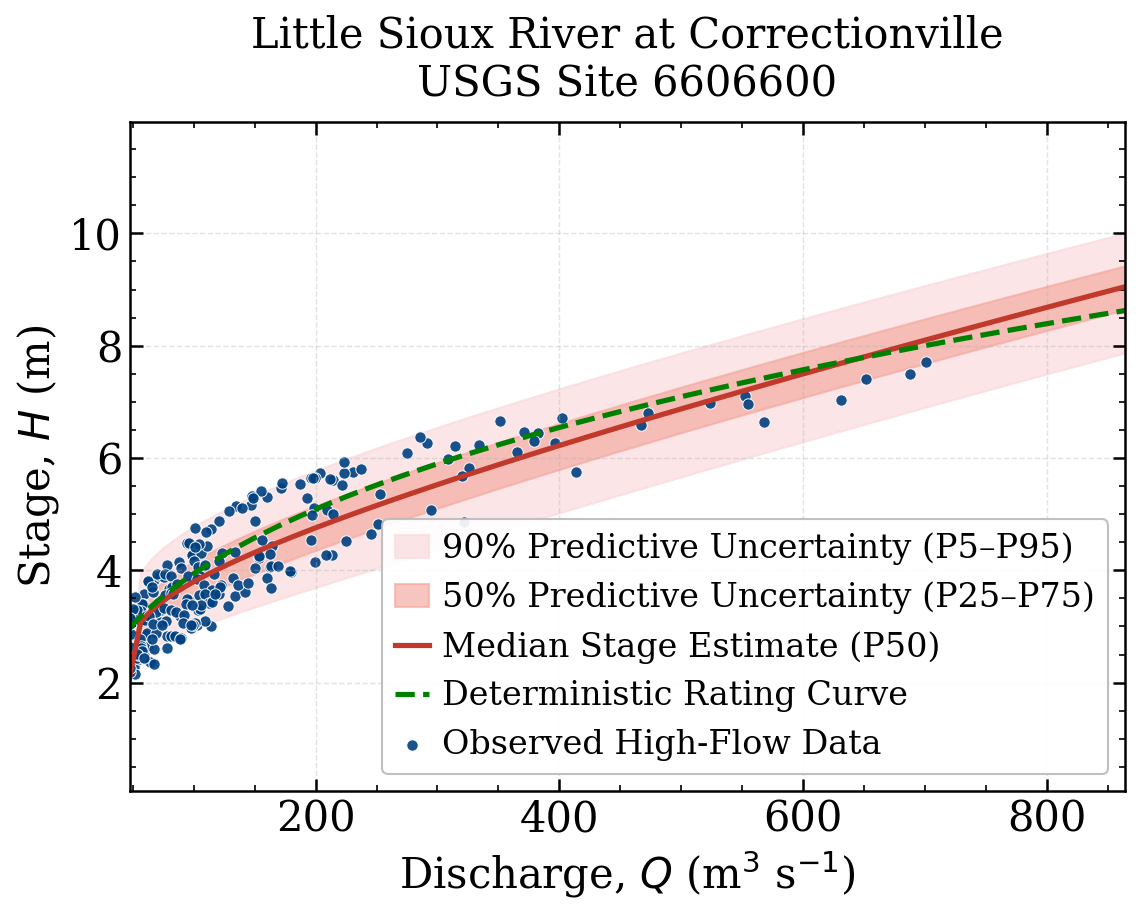

In [30]:
import matplotlib.ticker as ticker

plt.rcParams.update({
    'font.family':        'serif',
    'font.serif':         ['Times New Roman', 'DejaVu Serif'],
    'font.size':          20,
    'axes.titlesize':     20,
    'axes.labelsize':     20,
    'xtick.labelsize':    20,
    'ytick.labelsize':    20,
    'legend.fontsize':    16,
    'axes.linewidth':     1.2,
    'xtick.major.width':  1.2,
    'ytick.major.width':  1.2,
    'xtick.minor.width':  0.8,
    'ytick.minor.width':  0.8,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   6,
    'ytick.major.size':   6,
    'xtick.minor.size':   3,
    'ytick.minor.size':   3,
    'xtick.top':          True,
    'ytick.right':        True,
    'axes.grid':          True,
    'grid.alpha':         0.35,
    'grid.linestyle':     '--',
    'grid.linewidth':     0.7,
    'figure.dpi':         150,
    'savefig.dpi':        300,
    'savefig.bbox':       'tight',
})

best_name  = score_cop_df.iloc[0]['family']
best_model = models_cop[best_name]
best_bic   = score_cop_df.iloc[0]['BIC']

discharge_data = df_clean["x"].values
stage_data     = df_clean["y"].values

q_min = float(np.nanmin(discharge_data))
q_max = float(np.nanmax(discharge_data))
q_pad = (q_max - q_min) * 0.25
discharge_grid = np.linspace(max(0.0, q_min), q_max + q_pad, 90)

qs    = (0.05, 0.25, 0.50, 0.75, 0.95)
preds = np.full((len(discharge_grid), len(qs)), np.nan)

for i, qv in enumerate(tqdm(discharge_grid, desc="Computing quantiles") if _HAS_TQDM else discharge_grid):
    h_grid, pdf = predict_conditional_stage_pdf(qv, ux, uy, best_model, n_points=800)
    preds[i, :] = quantiles_from_pdf(h_grid, pdf, qs=qs)

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.fill_between(discharge_grid, preds[:, 0], preds[:, 4],
                color='#FADADD', alpha=0.7,
                label='90% Predictive Uncertainty (P5–P95)')
ax.fill_between(discharge_grid, preds[:, 1], preds[:, 3],
                color='#F4A79D', alpha=0.65,
                label='50% Predictive Uncertainty (P25–P75)')
ax.plot(discharge_grid, preds[:, 2],
        color='#C0392B', lw=2.5,
        label='Median Stage Estimate (P50)')

if rc_q_extended is not None:
    ax.plot(rc_q_extended, rc_h_extended,
            "g--", lw=2.5, label='Deterministic Rating Curve')

ax.scatter(discharge_data, stage_data,
           s=30, alpha=0.9, color='#004080',
           label='Observed High-Flow Data',
           edgecolors='w', linewidth=0.5)

y_min = np.nanmin([np.nanmin(preds[:, 0]), np.nanmin(stage_data)])
y_max = np.nanmax([np.nanmax(preds[:, 4]), np.nanmax(stage_data)])
y_pad = 0.25 * (y_max - y_min)
ax.set_ylim(y_min - y_pad, y_max + y_pad)
ax.set_xlim(discharge_grid.min(), discharge_grid.max())

ax.set_xlabel('Discharge, $Q$ (m$^3$ s$^{-1}$)')
ax.set_ylabel('Stage, $H$ (m)')
ax.set_title('Little Sioux River at Correctionville\n'
             f'USGS Site {TARGET_SITE}', pad=12)

ax.legend(loc='lower right', frameon=True,
          framealpha=0.92, edgecolor='#bbbbbb',
          handlelength=1.0,
          handletextpad=0.4)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))

plt.tight_layout()
plt.savefig(f'GUMBEL-{TARGET_SITE}.png', dpi=300, bbox_inches='tight')
print(f"Figure saved to GUMBEL-{TARGET_SITE}.png")
plt.show()

Computing quantiles:   0%|          | 0/90 [00:00<?, ?it/s]

/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


At Q = 400 m³/s:
  5th Percentile = 5.02 m
  95th Percentile = 7.23 m
Figure saved to GUMBEL-6606600_Q400.png


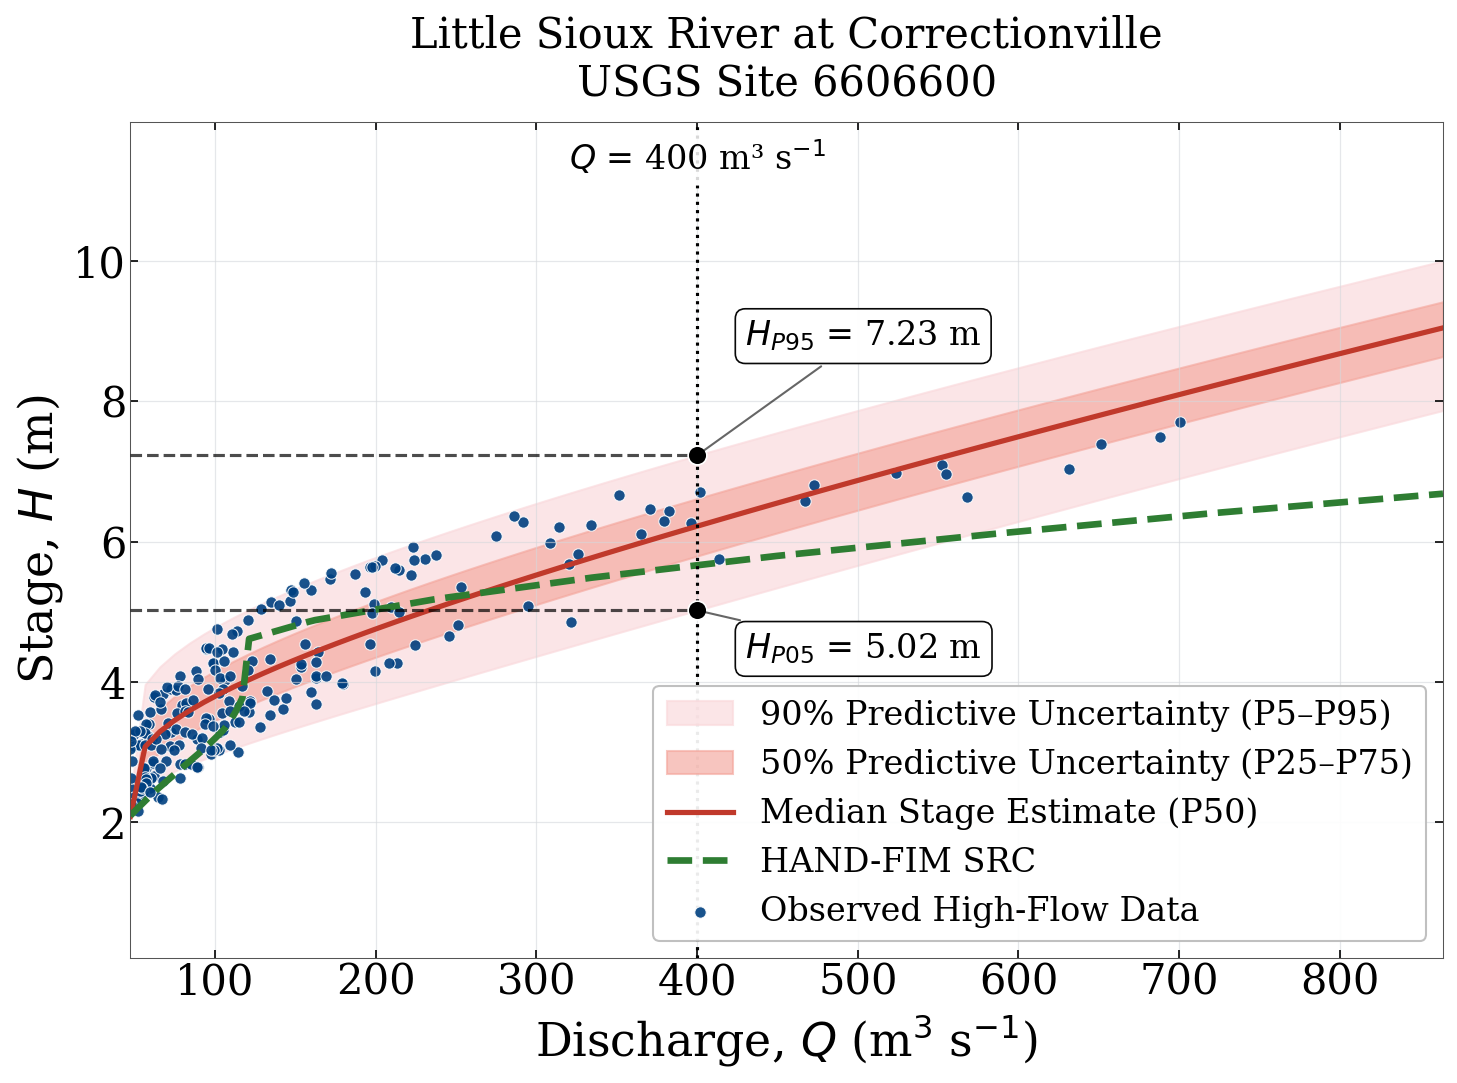

In [32]:
import matplotlib.ticker as ticker

# rcParams matched to the multi-site cells
plt.rcParams.update({
    'font.family':        'serif',
    'font.serif':         ['Times New Roman', 'DejaVu Serif'],
    'font.size':          16,
    'axes.titlesize':     15,
    'axes.labelsize':     17,
    'xtick.labelsize':    15,
    'ytick.labelsize':    15,
    'legend.fontsize':    14,
    'xtick.major.width':  1.2,
    'ytick.major.width':  1.2,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   6,
    'ytick.major.size':   6,
    'xtick.top':          True,
    'ytick.right':        True,
    'figure.dpi':         150,
    'savefig.dpi':        300,
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.grid':          True,
    'grid.color':         '#D5D8DC',
    'grid.linestyle':     '-',
    'grid.linewidth':     0.6,
    'grid.alpha':         0.6,
    'axes.linewidth':     0.5,
    'axes.edgecolor':     '#555555',
    'axes.spines.top':    True,
    'axes.spines.right':  True,
})

# --- SRC from HAND-FIM (Little Sioux at Correctionville, USGS 06606600) ---
src_6606600 = """1.352337 0.3048
4.859541 0.6096
10.26505 0.9144
17.46265 1.2192
26.26562 1.524
36.85817 1.8288
48.86376 2.1336
62.43736 2.4384
77.69509 2.7432
93.30218 3.048
106.9859 3.3528
114.9087 3.6576
120.4087 3.9624
106.0238 4.2672
114.6553 4.572
160.8202 4.8768
237.2388 5.1816
333.8784 5.4864
446.8134 5.7912
577.5016 6.096
717.5469 6.4008
875.0098 6.7056
1041.264 7.0104
1221.822 7.3152
1416.775 7.62
1632.342 7.9248
1874.489 8.2296
2127.055 8.5344
2391.368 8.8392
2662.203 9.144
2929.902 9.4488
3177.191 9.7536
3465.597 10.0584"""

src_arr = np.array([row.split() for row in src_6606600.strip().split('\n')],
                   dtype=float)
src_q = src_arr[:, 0]
src_h = src_arr[:, 1]

# Drop the small bank-overflow region where Q briefly decreases so the
# SRC is strictly monotonic in Q (required for np.interp to work cleanly)
mono = np.concatenate([[True], np.diff(src_q) > 0])
src_q = src_q[mono]
src_h = src_h[mono]

best_name  = score_cop_df.iloc[0]['family']
best_model = models_cop[best_name]
best_bic   = score_cop_df.iloc[0]['BIC']

discharge_data = df_clean["x"].values
stage_data     = df_clean["y"].values

q_min = float(np.nanmin(discharge_data))
q_max = float(np.nanmax(discharge_data))
q_pad = (q_max - q_min) * 0.25
discharge_grid = np.linspace(max(0.0, q_min), q_max + q_pad, 90)

qs    = (0.05, 0.25, 0.50, 0.75, 0.95)
preds = np.full((len(discharge_grid), len(qs)), np.nan)

for i, qv in enumerate(tqdm(discharge_grid, desc="Computing quantiles") if _HAS_TQDM else discharge_grid):
    h_grid, pdf = predict_conditional_stage_pdf(qv, ux, uy, best_model, n_points=800)
    preds[i, :] = quantiles_from_pdf(h_grid, pdf, qs=qs)

# Build SRC line that matches the pink-band x-extent
x_lo = discharge_grid.min()
x_hi = discharge_grid.max()
src_lo = max(x_lo, src_q.min())
src_hi = min(x_hi, src_q.max())
src_q_plot = np.linspace(src_lo, src_hi, 200)
src_h_plot = np.interp(src_q_plot, src_q, src_h)

fig, ax = plt.subplots(figsize=(10, 7.5))

# --- Probabilistic curves ---
ax.fill_between(discharge_grid, preds[:, 0], preds[:, 4],
                color='#FADADD', alpha=0.7,
                label='90% Predictive Uncertainty (P5–P95)')
ax.fill_between(discharge_grid, preds[:, 1], preds[:, 3],
                color='#F4A79D', alpha=0.65,
                label='50% Predictive Uncertainty (P25–P75)')
ax.plot(discharge_grid, preds[:, 2],
        color='#C0392B', lw=2.5,
        label='Median Stage Estimate (P50)')

# --- HAND-FIM SRC ---
ax.plot(src_q_plot, src_h_plot,
        color='#2E7D32', lw=3.2, ls='--',
        label='HAND-FIM SRC')

ax.scatter(discharge_data, stage_data,
           s=30, alpha=0.9, color='#004080',
           edgecolors='w', linewidth=0.5,
           label='Observed High-Flow Data')

y_min = np.nanmin([np.nanmin(preds[:, 0]), np.nanmin(stage_data),
                   np.nanmin(src_h_plot)])
y_max = np.nanmax([np.nanmax(preds[:, 4]), np.nanmax(stage_data),
                   np.nanmax(src_h_plot)])
y_pad = 0.25 * (y_max - y_min)
ax.set_ylim(y_min - y_pad, y_max + y_pad)
ax.set_xlim(discharge_grid.min(), discharge_grid.max())

# --- Q target ---
Q_target = 400

h_grid_t, pdf_t = predict_conditional_stage_pdf(Q_target, ux, uy, best_model, n_points=800)
p05, p95 = quantiles_from_pdf(h_grid_t, pdf_t, qs=[0.05, 0.95])

print(f"At Q = {Q_target} m³/s:")
print(f"  5th Percentile = {p05:.2f} m")
print(f"  95th Percentile = {p95:.2f} m")

x_left = discharge_grid.min()

ax.axvline(x=Q_target, color='black', linewidth=1.5, linestyle=':', zorder=4)
ax.text(Q_target, ax.get_ylim()[1] * 0.98,
        f'$Q$ = {Q_target} m³ s$^{{-1}}$',
        fontsize=16, color='black', ha='center', va='top', zorder=10,
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85))

for stage, label, y_offset in zip(
        [p05, p95],
        ['$H_{{P05}}$ = {:.2f} m', '$H_{{P95}}$ = {:.2f} m'],
        [-0.55, 1.7]):

    ax.plot([x_left, Q_target], [stage, stage],
            color='black', linewidth=1.5, linestyle='--',
            alpha=0.7, zorder=5)

    ax.plot(Q_target, stage, 'o', color='black', markersize=9,
            zorder=9, markeredgecolor='white', markeredgewidth=0.8)

    ax.annotate(label.format(stage),
                xy=(Q_target, stage),
                xytext=(Q_target + 30, stage + y_offset),
                fontsize=16, color='black', va='center', zorder=10,
                bbox=dict(boxstyle='round,pad=0.3', fc='white',
                          ec='black', linewidth=0.8, alpha=0.97),
                arrowprops=dict(arrowstyle='-', color='black',
                                lw=1.0, alpha=0.6))

# --- Labels / title / ticks / legend — matched to multi-site cells ---
ax.set_xlabel('Discharge, $Q$ (m$^3$ s$^{-1}$)', fontsize=22)
ax.set_ylabel('Stage, $H$ (m)', fontsize=22)
ax.set_title('Little Sioux River at Correctionville\n'
             f'USGS Site {TARGET_SITE}', fontsize=20, pad=12)
ax.tick_params(labelsize=20, pad=2, length=4, width=0.8)
ax.legend(loc='lower right', fontsize=16, frameon=True,
          framealpha=0.92, edgecolor='#bbbbbb')

plt.tight_layout()
plt.savefig(f'GUMBEL-{TARGET_SITE}_Q{Q_target}.png', dpi=300, bbox_inches='tight')
print(f"Figure saved to GUMBEL-{TARGET_SITE}_Q{Q_target}.png")
plt.show()

Computing quantiles:   0%|          | 0/90 [00:00<?, ?it/s]

/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


Figure saved to SRC_COMPARE_6606600.png


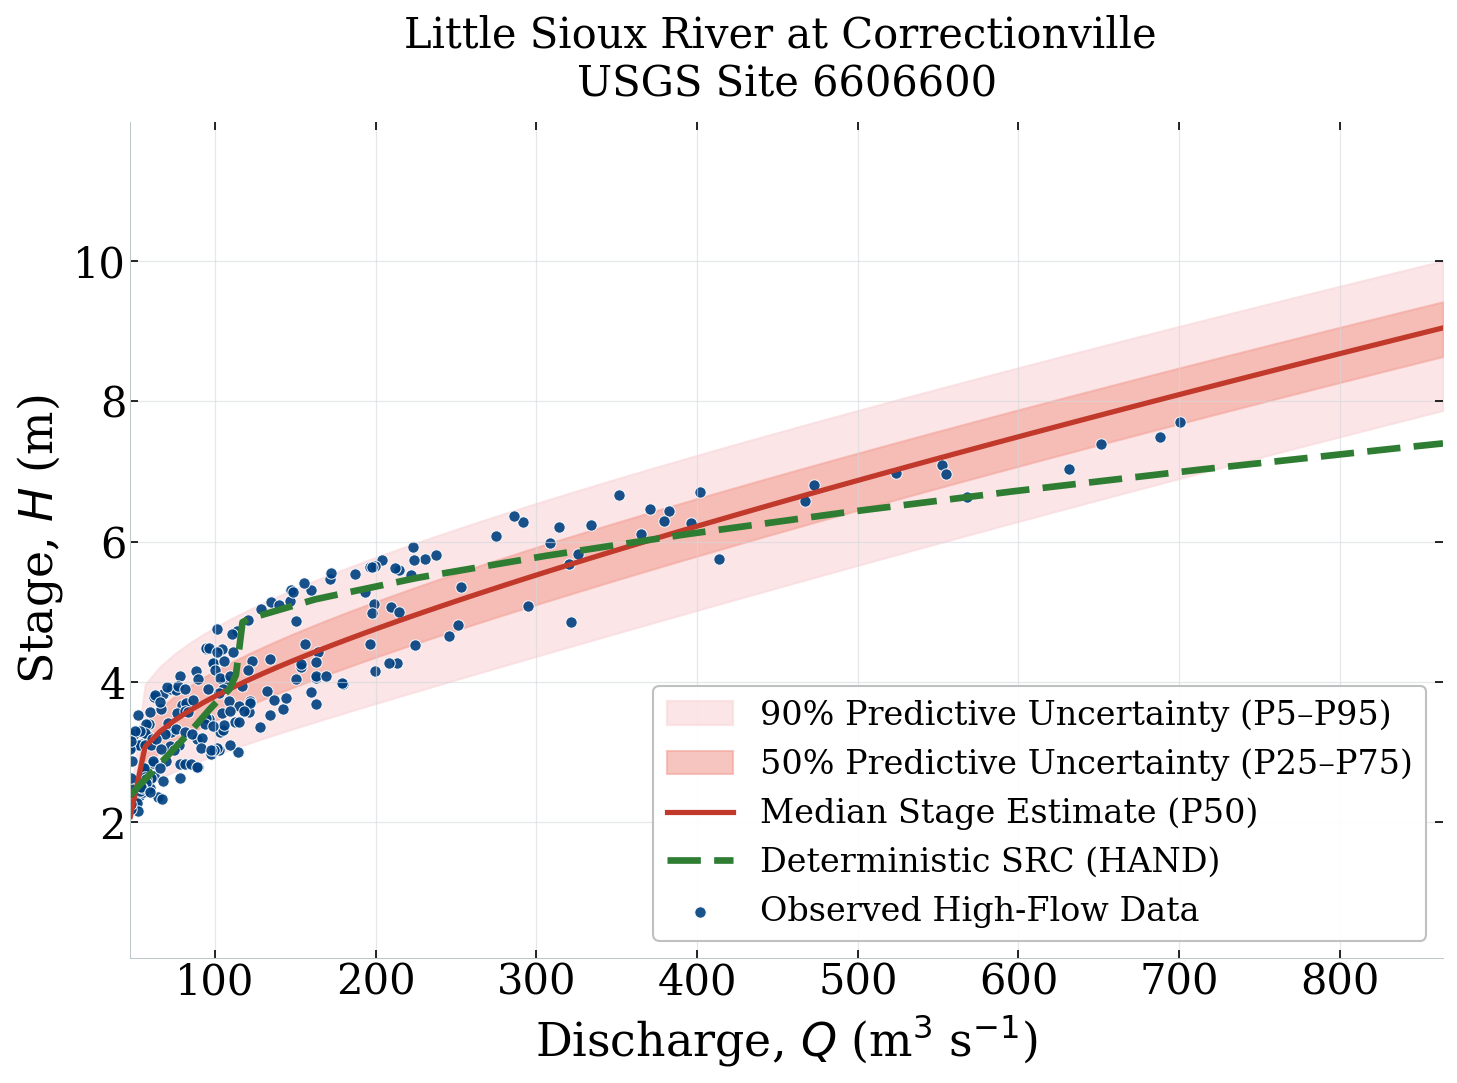

In [34]:
import matplotlib.ticker as ticker

# rcParams matched to the multi-site cells
plt.rcParams.update({
    'font.family':        'serif',
    'font.serif':         ['Times New Roman', 'DejaVu Serif'],
    'font.size':          16,
    'axes.titlesize':     15,
    'axes.labelsize':     17,
    'xtick.labelsize':    15,
    'ytick.labelsize':    15,
    'legend.fontsize':    14,
    'xtick.major.width':  1.2,
    'ytick.major.width':  1.2,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   6,
    'ytick.major.size':   6,
    'xtick.top':          True,
    'ytick.right':        True,
    'figure.dpi':         150,
    'savefig.dpi':        300,
    'figure.facecolor':   'white',
    'axes.facecolor':     'white',
    'axes.grid':          True,
    'grid.color':         '#D5D8DC',
    'grid.linestyle':     '-',
    'grid.linewidth':     0.6,
    'grid.alpha':         0.6,
    'axes.linewidth':     0.5,
    'axes.edgecolor':     '#BFC9CA',
    'axes.spines.top':    False,
    'axes.spines.right':  False,
})

# ==================================================================
# Only candidate C is kept
# ==================================================================
src_C = """0.3048\t0.965595376
0.6096\t3.586245031
0.9144\t7.747252208
1.2192\t13.34527637
1.524\t20.26025577
1.8288\t28.55306813
2.1336\t38.3384907
2.4384\t49.32622865
2.7432\t62.00948473
3.048\t74.64202779
3.3528\t86.95011986
3.6576\t98.40872742
3.9624\t111.8012252
4.2672\t114.4168028
4.572\t99.63743757
4.8768\t117.1872005
5.1816\t162.7521759
5.4864\t226.0367904
5.7912\t303.562109
6.096\t390.015479
6.4008\t486.2451971
6.7056\t591.6834025
7.0104\t705.730581
7.3152\t827.7742542
7.62\t955.4837524
7.9248\t1091.363591
8.2296\t1238.768664
8.5344\t1393.612251
8.8392\t1557.957801
9.144\t1729.191437
9.4488\t1908.471015
9.7536\t2092.399978
10.0584\t2283.797709
10.3632\t2483.738162
10.668\t2690.220326
10.9728\t2902.449765"""

def parse_src(raw):
    """Parse an (H, Q) SRC and return a monotonic Q-H curve.

    Walks the table in its original H-increasing order and keeps only
    rows where Q is strictly greater than the previous kept Q. This
    removes the bank-overflow region where the HAND SRC briefly reverses,
    leaving both Q and H monotonically increasing so np.interp produces
    a smooth curve.
    """
    arr = np.array([row.split() for row in raw.strip().split('\n')],
                   dtype=float)
    h_all, q_all = arr[:, 0], arr[:, 1]

    keep_q, keep_h = [q_all[0]], [h_all[0]]
    for h, q in zip(h_all[1:], q_all[1:]):
        if q > keep_q[-1]:
            keep_q.append(q)
            keep_h.append(h)

    return np.array(keep_q), np.array(keep_h)

src_q_C, src_h_C = parse_src(src_C)

best_name  = score_cop_df.iloc[0]['family']
best_model = models_cop[best_name]
best_bic   = score_cop_df.iloc[0]['BIC']

discharge_data = df_clean["x"].values
stage_data     = df_clean["y"].values

q_min = float(np.nanmin(discharge_data))
q_max = float(np.nanmax(discharge_data))
q_pad = (q_max - q_min) * 0.25
discharge_grid = np.linspace(max(0.0, q_min), q_max + q_pad, 90)

qs    = (0.05, 0.25, 0.50, 0.75, 0.95)
preds = np.full((len(discharge_grid), len(qs)), np.nan)

for i, qv in enumerate(tqdm(discharge_grid, desc="Computing quantiles") if _HAS_TQDM else discharge_grid):
    h_grid, pdf = predict_conditional_stage_pdf(qv, ux, uy, best_model, n_points=800)
    preds[i, :] = quantiles_from_pdf(h_grid, pdf, qs=qs)

x_lo = discharge_grid.min()
x_hi = discharge_grid.max()

def src_line(src_q, src_h):
    lo = max(x_lo, src_q.min())
    hi = min(x_hi, src_q.max())
    qq = np.linspace(lo, hi, 200)
    hh = np.interp(qq, src_q, src_h)
    return qq, hh

q_line_C, h_line_C = src_line(src_q_C, src_h_C)

fig, ax = plt.subplots(figsize=(10, 7.5))

# Probabilistic curves
ax.fill_between(discharge_grid, preds[:, 0], preds[:, 4],
                color='#FADADD', alpha=0.7,
                label='90% Predictive Uncertainty (P5–P95)')
ax.fill_between(discharge_grid, preds[:, 1], preds[:, 3],
                color='#F4A79D', alpha=0.65,
                label='50% Predictive Uncertainty (P25–P75)')
ax.plot(discharge_grid, preds[:, 2],
        color='#C0392B', lw=2.5,
        label='Median Stage Estimate (P50)')

# Only candidate C – colored green like the original A
ax.plot(q_line_C, h_line_C,
        color='#2E7D32', lw=3.2, ls=(0, (5, 2)),   # green color, keep C's original dash pattern
        label='Deterministic SRC (HAND)')

ax.scatter(discharge_data, stage_data,
           s=30, alpha=0.9, color='#004080',
           edgecolors='w', linewidth=0.5,
           label='Observed High-Flow Data')

y_min = np.nanmin([np.nanmin(preds[:, 0]), np.nanmin(stage_data), np.nanmin(h_line_C)])
y_max = np.nanmax([np.nanmax(preds[:, 4]), np.nanmax(stage_data), np.nanmax(h_line_C)])
y_pad = 0.25 * (y_max - y_min)
ax.set_ylim(y_min - y_pad, y_max + y_pad)
ax.set_xlim(discharge_grid.min(), discharge_grid.max())

# Labels / title / ticks / legend
ax.set_xlabel('Discharge, $Q$ (m$^3$ s$^{-1}$)', fontsize=22)
ax.set_ylabel('Stage, $H$ (m)', fontsize=22)
ax.set_title('Little Sioux River at Correctionville \n'
             f'USGS Site {TARGET_SITE}', fontsize=20, pad=12)
ax.tick_params(labelsize=20, pad=2, length=4, width=0.8)
ax.legend(loc='lower right', fontsize=16, frameon=True,
          framealpha=0.92, edgecolor='#bbbbbb')

plt.tight_layout()
plt.savefig(f'SRC_COMPARE_{TARGET_SITE}.png', dpi=300, bbox_inches='tight')
print(f"Figure saved to SRC_COMPARE_{TARGET_SITE}.png")
plt.show()

In [36]:
# --- NSE Calculation for Probabilistic Rating Curve ---
from sklearn.metrics import r2_score # NSE is mathematically equivalent to R^2

# Calculate predicted median stage for all observed high-flow discharges
h_preds_median = []
for q_obs in df_clean["x"].values:
    h_grid, pdf = predict_conditional_stage_pdf(q_obs, ux, uy, best_model)
    p50 = quantiles_from_pdf(h_grid, pdf, qs=[0.50])[0]
    h_preds_median.append(p50)

nse_value = r2_score(df_clean["y"].values, h_preds_median)
print(f"Nash-Sutcliffe Efficiency (NSE): {nse_value:.3f}")

/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


Nash-Sutcliffe Efficiency (NSE): 0.812


In [37]:
# --- Coverage and Spread Calculation ---
covered_95 = 0
spreads_95 = []

for i, q_obs in enumerate(df_clean["x"].values):
    h_obs = df_clean["y"].values[i]
    h_grid, pdf = predict_conditional_stage_pdf(q_obs, ux, uy, best_model)

    # Get 95% bounds (P2.5 and P97.5)
    bounds = quantiles_from_pdf(h_grid, pdf, qs=[0.025, 0.975])

    # Check if observation is within bounds
    if bounds[0] <= h_obs <= bounds[1]:
        covered_95 += 1

    spreads_95.append(bounds[1] - bounds[0])

coverage_pct = (covered_95 / len(df_clean)) * 100
avg_spread = np.mean(spreads_95)

print(f"95% Prediction Coverage: {coverage_pct:.2f}%")
print(f"Average 95% Spread: {avg_spread:.2f} meters")

/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


95% Prediction Coverage: 95.48%
Average 95% Spread: 2.20 meters


In [39]:
# ==============================================================================
# CELL A: Predict Conditional STAGE from SRC DISCHARGE (COMPATIBLE VERSION)
# ==============================================================================
import numpy as np
import pandas as pd
from io import StringIO
from tqdm.notebook import tqdm

# --- 1. Bridge and Setup check ---
# Map the plotting function names to the names used in this cell
predict_conditional_stage = predict_conditional_stage_pdf
get_quantiles_from_density = quantiles_from_pdf

# Automatically select the best model based on the lowest BIC from your previous step
try:
    best_model_name = score_cop_df.iloc[0]['family']
    best_model = models_cop[best_model_name]
    print(f"✅ Ready. Using the '{best_model_name}' copula (lowest BIC) for predictions.")
except Exception as e:
    raise RuntimeError(f"Missing required objects. Ensure the plotting cell ran successfully. Error: {e}")

# --- 2. SRC stage-discharge data ---
src_data = """
0.3048  1.352336774
0.6096  4.859541382
0.9144  10.26504817
1.2192  17.46264799
1.524 26.26562311
1.8288  36.85817337
2.1336  48.86376205
2.4384  62.43736214
2.7432  77.69508551
3.048 93.30218049
3.3528  106.9858924
3.6576  114.9087315
3.9624  120.4087142
4.2672  106.0237834
4.572 114.6553327
4.8768  160.8202101
5.1816  237.2387793
5.4864  333.8784163
5.7912  446.8134328
6.096 577.5016209
6.4008  717.5468746
6.7056  875.0098187
7.0104  1041.263913
7.3152  1221.822278
7.62   1416.774878
7.9248  1632.341582
8.2296  1874.488793
8.5344  2127.054912
8.8392  2391.368213
9.144 2662.202573
9.4488  2929.902447
9.7536  3177.190802
10.0584 3465.596722
10.3632 3779.79078
10.668  4128.254318
10.9728 4520.623837
11.2776 4941.609037
11.5824 5376.204978
11.8872 5829.947126
12.192  6298.794239
12.4968 6782.588592
12.8016 7280.692775
13.1064 7792.873712
13.4112 8319.605999
13.716  8857.782723
14.0208 9411.229274
14.3256 9977.607142
14.6304 10556.59667
14.9352 11150.04869
15.24 11758.13897
15.5448 12377.72137
15.8496 13009.10848
16.1544 13654.81473
16.4592 14314.16629
16.764  14986.82752
17.0688 15670.18675
17.3736 16365.46975
17.6784 17068.68589
17.9832 17792.92956
18.288  18520.8536
18.5928 19260.46498
18.8976 20014.3779
19.2024 20788.22298
19.5072 21569.57713
19.812  22358.36539
20.1168 23162.89368
20.4216 23972.84502
20.7264 24800.50549
21.0312 25637.87973
21.336  26486.28332
21.6408 27338.72208
21.9456 28215.09385
22.2504 29091.10578
22.5552 29987.73617
22.86 30891.33561
23.1648 31807.88686
23.4696 32729.13306
23.7744 33656.55171
24.0792 34598.87739
24.384  35556.25628
24.6888 36531.62677
24.9936 37512.76678
25.2984 38494.46161
"""

src_arr = np.loadtxt(StringIO(src_data))
src_stage = src_arr[:, 0]
src_discharge = src_arr[:, 1]

# --- 3. Perform copula predictions ---
quantiles_to_find = [0.05, 0.25, 0.50, 0.75, 0.95]

# --- PART 1: Predictions for SRC data ---
print(f"\nStarting copula prediction for {len(src_discharge)} SRC discharge values...")
results_list_src = []

for stage_val, q_value in tqdm(zip(src_stage, src_discharge), total=len(src_discharge), desc="Predicting Stage (SRC)"):
    # Using the bridged function name
    stage_grid, predicted_density = predict_conditional_stage(q_value, ux, uy, best_model)
    result_row = {"SRC_Discharge_m3s": q_value, "SRC_Stage_m": stage_val}

    if np.sum(predicted_density) > 1e-8:
        # Using the bridged function name
        stage_values = get_quantiles_from_density(stage_grid, predicted_density, quantiles_to_find)
        result_row["Copula_Stage_p05_m"] = stage_values[0]
        result_row["Copula_Stage_p25_m"] = stage_values[1]
        result_row["Copula_Stage_Median_m"] = stage_values[2]
        result_row["Copula_Stage_p75_m"] = stage_values[3]
        result_row["Copula_Stage_p95_m"] = stage_values[4]
    else:
        for k in ["Copula_Stage_p05_m", "Copula_Stage_p25_m", "Copula_Stage_Median_m", "Copula_Stage_p75_m", "Copula_Stage_p95_m"]:
            result_row[k] = np.nan

    results_list_src.append(result_row)

results_df_stage_pred = pd.DataFrame(results_list_src)

# --- PART 2: Predictions for Generic 50 m3/s Grid ---
print("\nStarting copula prediction for generic 50 m3/s grid...")
max_q = np.max(src_discharge)
q_grid_50 = np.arange(50, max_q + 50, 50)

results_list_50 = []
for q_value in tqdm(q_grid_50, desc="Predicting Stage (Generic Grid)"):
    stage_grid, predicted_density = predict_conditional_stage(q_value, ux, uy, best_model)
    result_row = {"Generic_Discharge_m3s": q_value}

    if np.sum(predicted_density) > 1e-8:
        stage_values = get_quantiles_from_density(stage_grid, predicted_density, quantiles_to_find)
        result_row["Generic_Stage_p05_m"] = stage_values[0]
        result_row["Generic_Stage_p25_m"] = stage_values[1]
        result_row["Generic_Stage_Median_m"] = stage_values[2]
        result_row["Generic_Stage_p75_m"] = stage_values[3]
        result_row["Generic_Stage_p95_m"] = stage_values[4]
    else:
        for k in ["Generic_Stage_p05_m", "Generic_Stage_p25_m", "Generic_Stage_Median_m", "Generic_Stage_p75_m", "Generic_Stage_p95_m"]:
            result_row[k] = np.nan

    results_list_50.append(result_row)

results_df_50_pred = pd.DataFrame(results_list_50)

# --- 4. Combine and Save results ---
results_df_stage_pred[''] = np.nan
final_results_df = pd.concat([
    results_df_stage_pred,
    results_df_50_pred.reset_index(drop=True)
], axis=1)

output_csv_path = "/content/drive/MyDrive/IFMHA/huc&hydtotable/copula_predictions_stage_given_discharge_Stite6606600.csv"
final_results_df.to_csv(output_csv_path, index=False)

print("\n--- First 5 rows of COMBINED prediction results ---")
print(final_results_df.head())
print(f"\n✅ Saved results using the best Copula model to: {output_csv_path}")

✅ Ready. Using the 'gumbel' copula (lowest BIC) for predictions.

Starting copula prediction for 83 SRC discharge values...


Predicting Stage (SRC):   0%|          | 0/83 [00:00<?, ?it/s]


Starting copula prediction for generic 50 m3/s grid...


/tmp/ipykernel_1880/2363739969.py:106: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(cond, stage_grid)


Predicting Stage (Generic Grid):   0%|          | 0/770 [00:00<?, ?it/s]


--- First 5 rows of COMBINED prediction results ---
   SRC_Discharge_m3s  SRC_Stage_m  Copula_Stage_p05_m  Copula_Stage_p25_m  \
0           1.352337       0.3048            2.058161            2.058161   
1           4.859541       0.6096            2.058161            2.058161   
2          10.265048       0.9144            2.058161            2.058161   
3          17.462648       1.2192            2.058161            2.058161   
4          26.265623       1.5240            2.058161            2.058161   

   Copula_Stage_Median_m  Copula_Stage_p75_m  Copula_Stage_p95_m      \
0               2.076848            2.127511            2.335205 NaN   
1               2.076848            2.127511            2.335205 NaN   
2               2.076848            2.127511            2.335205 NaN   
3               2.076848            2.127511            2.335205 NaN   
4               2.076848            2.127511            2.335205 NaN   

   Generic_Discharge_m3s  Generic_Stage_p05_m  Gene